Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)


cpu
Number of features: 110
(7713,)
(7713,)
Number of rows in features before: 7713
Number of rows in features after: 6968
Number of rows in labels: 6968
Number of rows in lats: 6968
Number of rows in lons: 6968
Test size ratio
0.25
Number of features: 110
(10836,)
(10836,)
Number of rows in features before: 10836
Number of rows in features after: 6173
Number of rows in labels: 6173
Number of rows in lats: 6173
Number of rows in lons: 6173
Test size ratio
0.25
features_toc shape: (21125, 110)
features_sedrate shape: (13141, 110)
The dimension of features_toc and features_sedrate are equal.
Training MTL model 0 with layer_widths=[512, 512, 512, 512] and num_shared_layers=4
(9855, 110)
Train Labels Distribution(Sedimentation Rates):
Count: 9855
Mean: 124.233
Std: 210.569
Min: 0.000
Max: 5070.000

Test Labels Distribution(Sedimentation Rates):
Count: 3286
Mean: 123.598
Std: 199.151
Min: 0.000
Max: 1794.000
Number of zeros in train labels: 27
Number of zeros in test labels: 8


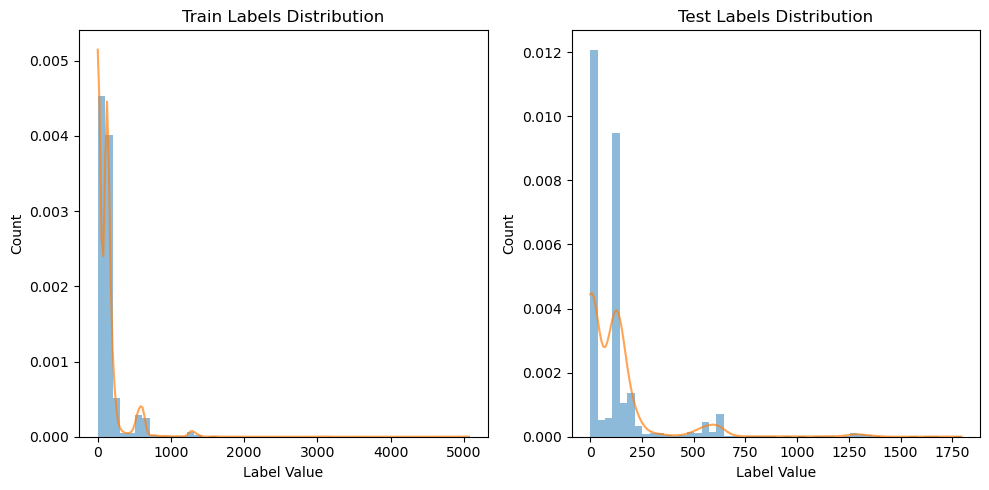

Train Labels Distribution(TOC):
Count: 15843
Mean: 0.726
Std: 1.122
Min: 0.000
Max: 20.200

Test Labels Distribution(TOC):
Count: 5282
Mean: 0.720
Std: 1.119
Min: 0.000
Max: 22.300
Number of zeros in train labels: 9
Number of zeros in test labels: 2


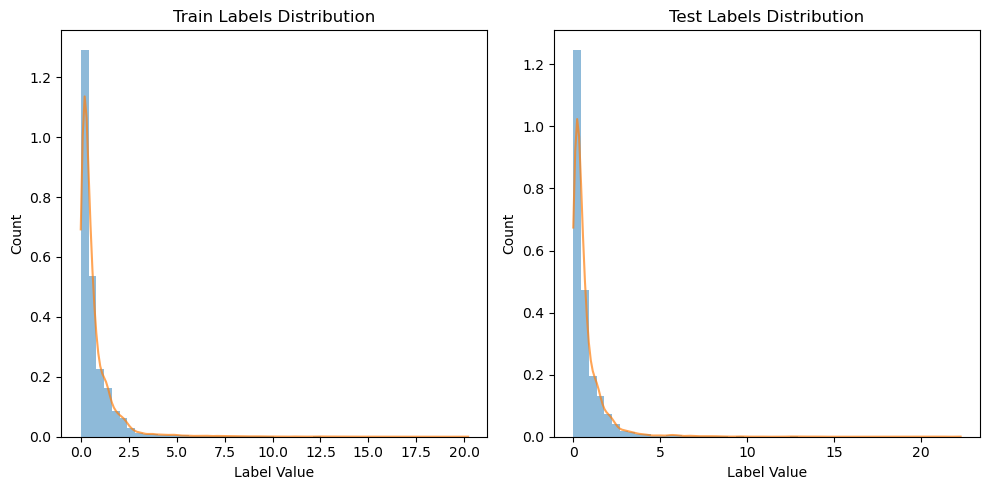

torch.Size([9855, 110])
torch.Size([9855])
1
MTLNN(
  (encoder): Sequential(
    (encoder_linear_0): Linear(in_features=110, out_features=512, bias=True)
    (encoder_relu_0): ReLU()
    (encoder_dropout_0): Dropout(p=0.2, inplace=False)
    (encoder_linear_1): Linear(in_features=512, out_features=512, bias=True)
    (encoder_relu_1): ReLU()
    (encoder_dropout_1): Dropout(p=0.2, inplace=False)
    (encoder_linear_2): Linear(in_features=512, out_features=512, bias=True)
    (encoder_relu_2): ReLU()
    (encoder_dropout_2): Dropout(p=0.2, inplace=False)
    (encoder_linear_3): Linear(in_features=512, out_features=512, bias=True)
    (encoder_relu_3): ReLU()
    (encoder_dropout_3): Dropout(p=0.2, inplace=False)
  )
  (task_sedimentation_rates_head): Sequential(
    (0): Linear(in_features=512, out_features=1, bias=True)
  )
  (task_toc_head): Sequential(
    (0): Linear(in_features=512, out_features=1, bias=True)
  )
)
2
[512, 512, 512, 512]
4
Task 1 : Sedimentation rates
Task 2 : TOC


In [1]:
# %%
import torch
import numpy as np
import pandas as pd
from pathlib import Path
from matplotlib import pyplot as plt
from torch.utils.data import TensorDataset, DataLoader
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.model_selection import StratifiedKFold, KFold, train_test_split
from sklearn.decomposition import PCA
import sys
import shap  # Add SHAP import for bee swarm plots


# Add project paths
models_path = Path().resolve().parents[1] / "src" / "models"
postproc_path = Path().resolve().parents[1] / "src" / "postprocessing"
sys.path.extend([str(models_path), str(postproc_path)])

# Import project modules
from trainMTL import *
from explainMTL import *
from predictDNN import *
from getModelPerformance import * 

porosity_fileidx = 83

# Set random seed for reproducibility
set_seed(42)


# Set device and torch backend options
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(device)
set_seed()
constraint = 0.1
layer_widths_all = [[512]*4]#[512]*6, [512]*7, [512]*8, [128]*3, [128]*4, [128]*5, [128]*6, [128]*7, [128]*8, [64]*3, [64]*4, [64]*5, [64]*6, [64]*7, [64]*8]
num_shared_layers_all = [4]#, 6, 7, 8]
# %%

# %% TOTAL ORGANIC CARBON
features_toc_CS = np.load("/gxfs_work/cau/sunms498/work/nn-toc-update/notebooks/TOC/preprocessed/features_CS_toc.npy")
labels_toc_CS = np.load("/gxfs_work/cau/sunms498/work/nn-toc-update/notebooks/TOC/preprocessed/labels_CS_toc.npy")
labels_mean_toc_CS = np.mean(labels_toc_CS)
labels_std_toc_CS = np.std(labels_toc_CS)

n_bins = 10
y_binned = pd.qcut(labels_toc_CS, q=n_bins, labels=False, duplicates='drop')
train_features_toc_CS, train_labels_toc_CS, test_features_toc_CS, test_labels_toc_CS = split_train_test_data(features_toc_CS, labels_toc_CS, test_size_ratio=0.25, random_seed=42, stratify=y_binned)
#trainloader, testloader = create_dataloaders(train_features, train_labels, test_features, test_labels, batch_size=batch_size, shuffle_train=True, shuffle_test=False)


features_toc_DO = np.load("/gxfs_work/cau/sunms498/work/nn-toc-update/notebooks/TOC/preprocessed/features_DO_toc.npy")
labels_toc_DO = np.load("/gxfs_work/cau/sunms498/work/nn-toc-update/notebooks/TOC/preprocessed/labels_DO_toc.npy")
labels_mean_toc_DO = np.mean(labels_toc_DO)
labels_std_toc_DO = np.std(labels_toc_DO)


y_binned = pd.qcut(labels_toc_DO, q=n_bins, labels=False, duplicates='drop')
train_features_toc_DO, train_labels_toc_DO, test_features_toc_DO, test_labels_toc_DO = split_train_test_data(features_toc_DO, labels_toc_DO, test_size_ratio=0.25, random_seed=42, stratify=y_binned)
#trainloader, testloader = create_dataloaders(train_features, train_labels, test_features, test_labels, batch_size=batch_size, shuffle_train=True, shuffle_test=False)


toc_train_features = np.concatenate([train_features_toc_CS, train_features_toc_DO], axis = 0)
toc_test_features = np.concatenate([test_features_toc_CS, test_features_toc_DO], axis = 0)
toc_train_labels = np.concatenate([train_labels_toc_CS, train_labels_toc_DO], axis = 0)
toc_test_labels = np.concatenate([test_labels_toc_CS, test_labels_toc_DO], axis = 0)

features_toc = np.concatenate([features_toc_CS, features_toc_DO], axis = 0)
labels_toc = np.concatenate([labels_toc_CS, labels_toc_DO], axis = 0)



# Load world features
dataset_path = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/worldfeatures/WorldFeaturesAllnoNaN_SedTOC_predict_men/")
files = sorted([f for f in dataset_path.iterdir() if f.is_file()])
features = np.load(files[0])
world_feature_shape_dim = features.shape[1]

#MASS ACCUMULATION RATES
feature_path = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/inputfeatures/SedTOCFeaturesnoNAN_MAR_DO_men/")
features = np.load(Path(feature_path / "numpy_features.npy"))
labels = np.load(Path(feature_path / "numpy_labels.npy"))
X_mean = np.load(feature_path / "features_mean.npy").astype(float)
X_std = np.load(feature_path / "features_std.npy").astype(float)
lats = np.load(feature_path / "numpy_lat.npy")
lons = np.load(feature_path / "numpy_lon.npy")
input_feature_shape_dim = features.shape[1]



if world_feature_shape_dim != input_feature_shape_dim:
    raise ValueError(f"Feature dimensions do not match: World features have {world_feature_shape_dim} dimensions while input features have {input_feature_shape_dim} dimensions")

print(f"Number of features: {features.shape[1]}")



features_DO, labels_DO, lats_DO, lons_DO = preprocess_features_labels(features, labels, lats, lons, X_mean, X_std)


from sklearn.model_selection import StratifiedKFold


test_size_ratio = 0.25
print("Test size ratio") 
print(test_size_ratio)

# Create bins for stratification
n_bins = 10
y_binned = pd.qcut(labels_DO, q=n_bins, labels=False, duplicates='drop')
train_features_DO, train_labels_DO, test_features_DO, test_labels_DO = split_train_test_data(features_DO, labels_DO, test_size_ratio=0.25, random_seed=42, stratify=y_binned)
#trainloader, testloader = create_dataloaders(train_features, train_labels, test_features, test_labels, batch_size=batch_size, shuffle_train=True, shuffle_test=False)




#  Load input feature 
feature_path = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/inputfeatures/SedTOCFeaturesnoNAN_MAR_CS_men/")
features = np.load(Path(feature_path / "numpy_features.npy"))
labels = np.load(Path(feature_path / "numpy_labels.npy"))
X_mean = np.load(feature_path / "features_mean.npy").astype(float)
X_std = np.load(feature_path / "features_std.npy").astype(float)
lats = np.load(feature_path / "numpy_lat.npy")
lons = np.load(feature_path / "numpy_lon.npy")
input_feature_shape_dim = features.shape[1]


if world_feature_shape_dim != input_feature_shape_dim:
    raise ValueError(f"Feature dimensions do not match: World features have {world_feature_shape_dim} dimensions while input features have {input_feature_shape_dim} dimensions")

print(f"Number of features: {features.shape[1]}")


features_CS, labels_CS, lats_CS, lons_CS = preprocess_features_labels(features, labels, lats, lons, X_mean, X_std)


from sklearn.model_selection import StratifiedKFold


test_size_ratio = 0.25
print("Test size ratio") 
print(test_size_ratio)

# Create bins for stratification
n_bins = 10
y_binned = pd.qcut(labels_CS, q=n_bins, labels=False, duplicates='drop')
train_features_CS, train_labels_CS, test_features_CS, test_labels_CS = split_train_test_data(features_CS, labels_CS, test_size_ratio=0.25, random_seed=42, stratify=y_binned)
#trainloader, testloader = create_dataloaders(train_features, train_labels, test_features, test_labels, batch_size=batch_size, shuffle_train=True, shuffle_test=False)

sedrate_train_features = np.concatenate([train_features_CS, train_features_DO], axis = 0)
sedrate_test_features = np.concatenate([test_features_CS, test_features_DO], axis = 0)
sedrate_train_labels = np.concatenate([train_labels_CS, train_labels_DO], axis = 0)
sedrate_test_labels = np.concatenate([test_labels_CS, test_labels_DO], axis = 0)
sedrate_features = np.concatenate([features_CS, features_DO], axis = 0)
sedrate_labels = np.concatenate([labels_CS, labels_DO], axis = 0)
#batch_size = 64
#trainloader, testloader = create_dataloaders(sedrate_train_features, sedrate_train_labels, sedrate_test_features, sedrate_test_labels, batch_size=batch_size, shuffle_train=True, shuffle_test=False)




dataset_path = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/worldfeatures/WorldFeaturesAllnoNaN_SedTOC_predict_men/")
files = []
for (dirpath, dirnames, filenames) in walk(dataset_path):
    files.extend(filenames)
    break
files.sort()
features = np.load(Path(dataset_path / files[0]))

print("features_toc shape:", features_toc.shape)
print("features_sedrate shape:", sedrate_features.shape)
if features_toc.shape[1] == sedrate_features.shape[1]:
    print("The dimension of features_toc and features_sedrate are equal.")
else:
    print(f"The dimension is not equal: features_toc.shape[1]={features_toc.shape[1]}, sedrate_features.shape[1]={sedrate_features.shape[1]}")




# %%

# Imparting constraints in the loss function. when porosity is greater than 0.6, sed rate is equal to zero.

import torch.nn.functional as F

class CombinedLoss(torch.nn.Module):
    def __init__(self, lambda_constraint):
        super(CombinedLoss, self).__init__()
        self.lambda_constraint = lambda_constraint
        self.loss_fn = {
            'sedimentation_rates': torch.nn.HuberLoss(),
            'toc': torch.nn.HuberLoss(),
        }
        self.MSELoss = torch.nn.MSELoss()
        self.L1Loss = torch.nn.L1Loss()

    def forward(self, features, labels, targets, decoded, porosity, train_step, task_id):


        fine_sand_porosity = -1.3026080219130773 #(0.55-X_mean)/X_std

        constraint_loss = torch.mean(torch.clamp(targets**2 * (fine_sand_porosity -porosity), min=0))  # Hinge loss
        mse_constant = torch.mean(torch.max(porosity, torch.tensor(fine_sand_porosity, device=porosity.device)) / torch.mean(porosity))
        
        if train_step == 1:
            features = torch.reshape(features, (features.shape[0]*features.shape[1],1))
            decoded = torch.reshape(decoded, (decoded.shape[0]*decoded.shape[1],1))
            reconstruction_loss = self.MSELoss(features, decoded)  # Example: using L1 loss
            combined_loss = reconstruction_loss# + self.lambda_constraint * constraint_loss
            
        elif train_step == 2:
            labels = torch.reshape(labels, (labels.shape[0],1))
            targets = torch.reshape(targets, (targets.shape[0],1))
            if task_id == "sedimentation_rates":
                regression_loss = self.loss_fn["sedimentation_rates"](labels, targets)
            if task_id == "toc":
                regression_loss = self.loss_fn["toc"](labels, targets)
            #combined_loss = mse_constant*regression_loss + self.lambda_constraint * constraint_loss #no constraint for deep sea
            combined_loss = regression_loss
            
        elif train_step == 3:
            features = torch.reshape(features, (features.shape[0]*features.shape[1],1))
            decoded = torch.reshape(decoded, (decoded.shape[0]*decoded.shape[1],1))
            labels = torch.reshape(labels, (labels.shape[0],1))
            targets = torch.reshape(targets, (targets.shape[0],1))
            regression_loss = self.L1Loss(labels, targets)
            reconstruction_loss = self.MSELoss(features, decoded)  # Example: using L1 loss
            combined_loss = reconstruction_loss + regression_loss + self.lambda_constraint * constraint_loss
            
        else:
            raise ValueError("Invalid train_step value.")
         
        return combined_loss

#loss_fn = CombinedLoss(lambda_constraint=constraint)#
loss_fn = torch.nn.HuberLoss()
"""
loss_fn = {
    'sedimentation_rates': torch.nn.L1Loss(),
    'toc': torch.nn.MSELoss(),
}
"""

def evaluate_model(model, data_loader, task, device):
    all_labels = []
    all_outputs = []

    model.eval()
    with torch.no_grad():
        for features, labels in data_loader:
            features = torch.tensor(features).to(device)
            features = features.to(dtype=torch.double)
            labels = labels.reshape(-1)

            decoded, outputs = model(features, task)
            outputs = outputs.cpu().numpy().reshape(-1)

            all_labels.extend(labels.cpu().detach().numpy())
            all_outputs.extend(outputs)
    #all_labels = all_labels.cpu().detach().numpy()
    all_labels = np.array(all_labels)
    #all_labels = all_labels.cpu().detach().numpy()
    all_outputs = np.array(all_outputs)

    mae = mean_absolute_error(all_labels, all_outputs)
    mse = mean_squared_error(all_labels, all_outputs)
    correlation = np.corrcoef(all_labels, all_outputs)[0, 1]
    r2 = r2_score(all_labels, all_outputs)

    return mae, mse, correlation, r2




# %%

count_mtl = 0
for layer_width in layer_widths_all:
    for num_shared_layers in num_shared_layers_all:
        print(f"Training MTL model {count_mtl} with layer_widths={layer_width} and num_shared_layers={num_shared_layers}")
        count_mtl = count_mtl + 1
        layer_widths = layer_width
        num_shared_layers = num_shared_layers
        if num_shared_layers > len(layer_widths):
            continue

        print(sedrate_train_features.shape)
        sedrate_train_features = torch.tensor(sedrate_train_features, dtype=torch.float32)
        sedrate_train_labels = torch.tensor(sedrate_train_labels, dtype=torch.float32)
        sedrate_test_features = torch.tensor(sedrate_test_features, dtype=torch.float32)
        sedrate_test_labels = torch.tensor(sedrate_test_labels, dtype=torch.float32)

        toc_train_features = torch.tensor(toc_train_features, dtype=torch.float32)
        toc_train_labels = torch.tensor(toc_train_labels, dtype=torch.float32)
        toc_test_features = torch.tensor(toc_test_features, dtype=torch.float32)
        toc_test_labels = torch.tensor(toc_test_labels, dtype=torch.float32)
        # Create TensorDatasets
        sedrate_train_dataset = TensorDataset(sedrate_train_features, sedrate_train_labels)
        sedrate_test_dataset = TensorDataset(sedrate_test_features, sedrate_test_labels)
        toc_train_dataset = TensorDataset(toc_train_features, toc_train_labels)
        toc_test_dataset = TensorDataset(toc_test_features, toc_test_labels)
        

        # Create DataLoaders
        batch_size = 32
        train_dataloaders = {
            'sedimentation_rates': DataLoader(sedrate_train_dataset, batch_size=batch_size, shuffle=True),
            'toc': DataLoader(toc_train_dataset, batch_size=batch_size, shuffle=True)
        }
        test_dataloaders = {
            'sedimentation_rates': DataLoader(sedrate_test_dataset, batch_size=batch_size, shuffle=False),
            'toc': DataLoader(toc_test_dataset, batch_size=batch_size, shuffle=False)
        }

        # Now you can use train_dataloaders and test_dataloaders in your training loop, e.g.:
        # for features, labels in train_dataloaders['sedimentation_rates']:
        #     # training step here

        # %%
        print("Train Labels Distribution(Sedimentation Rates):")
        print(f"Count: {len(sedrate_train_labels)}")
        print(f"Mean: {sedrate_train_labels.mean():.3f}")
        print(f"Std: {sedrate_train_labels.std():.3f}")
        print(f"Min: {sedrate_train_labels.min():.3f}")
        print(f"Max: {sedrate_train_labels.max():.3f}")
        print("\nTest Labels Distribution(Sedimentation Rates):")
        print(f"Count: {len(sedrate_test_labels)}")
        print(f"Mean: {sedrate_test_labels.mean():.3f}") 
        print(f"Std: {sedrate_test_labels.std():.3f}")
        print(f"Min: {sedrate_test_labels.min():.3f}")
        print(f"Max: {sedrate_test_labels.max():.3f}")

        # Plot histograms
        import matplotlib.pyplot as plt

        # Count number of zeros in train and test labels
        train_zeros = (sedrate_train_labels == 0).sum()
        test_zeros = (sedrate_test_labels == 0).sum()
        print(f"Number of zeros in train labels: {train_zeros}")
        print(f"Number of zeros in test labels: {test_zeros}")

        plt.figure(figsize=(10,5))
        from scipy.stats import gaussian_kde
        plt.subplot(1,2,1)
        plt.hist(sedrate_train_labels, bins=50, alpha=0.5, density=True)
        kde = gaussian_kde(sedrate_train_labels)
        x_range = np.linspace(min(sedrate_train_labels), max(sedrate_train_labels), 200)
        plt.plot(x_range, kde(x_range), alpha=0.7)
        plt.title('Train Labels Distribution')
        plt.xlabel('Label Value')
        plt.ylabel('Count')

        plt.subplot(1,2,2)
        plt.hist(sedrate_test_labels, bins=50, alpha=0.5, density=True)
        kde = gaussian_kde(sedrate_test_labels)
        x_range = np.linspace(min(sedrate_test_labels), max(sedrate_test_labels), 200)
        plt.plot(x_range, kde(x_range), alpha=0.7)
        plt.title('Test Labels Distribution')
        plt.xlabel('Label Value')
        plt.ylabel('Count')

        plt.tight_layout()
        plt.show()


        # %%
        print("Train Labels Distribution(TOC):")
        print(f"Count: {len(toc_train_labels)}")
        print(f"Mean: {toc_train_labels.mean():.3f}")
        print(f"Std: {toc_train_labels.std():.3f}")
        print(f"Min: {toc_train_labels.min():.3f}")
        print(f"Max: {toc_train_labels.max():.3f}")
        print("\nTest Labels Distribution(TOC):")
        print(f"Count: {len(toc_test_labels)}")
        print(f"Mean: {toc_test_labels.mean():.3f}") 
        print(f"Std: {toc_test_labels.std():.3f}")
        print(f"Min: {toc_test_labels.min():.3f}")
        print(f"Max: {toc_test_labels.max():.3f}")

        # Plot histograms
        import matplotlib.pyplot as plt

        # Count number of zeros in train and test labels
        train_zeros = (toc_train_labels == 0).sum()
        test_zeros = (toc_test_labels == 0).sum()
        print(f"Number of zeros in train labels: {train_zeros}")
        print(f"Number of zeros in test labels: {test_zeros}")

        plt.figure(figsize=(10,5))
        from scipy.stats import gaussian_kde
        plt.subplot(1,2,1)
        plt.hist(toc_train_labels, bins=50, alpha=0.5, density=True)
        kde = gaussian_kde(toc_train_labels)
        x_range = np.linspace(min(toc_train_labels), max(toc_train_labels), 200)
        plt.plot(x_range, kde(x_range), alpha=0.7)
        plt.title('Train Labels Distribution')
        plt.xlabel('Label Value')
        plt.ylabel('Count')

        plt.subplot(1,2,2)
        plt.hist(toc_test_labels, bins=50, alpha=0.5, density=True)
        kde = gaussian_kde(toc_test_labels)
        x_range = np.linspace(min(toc_test_labels), max(toc_test_labels), 200)
        plt.plot(x_range, kde(x_range), alpha=0.7)
        plt.title('Test Labels Distribution')
        plt.xlabel('Label Value')
        plt.ylabel('Count')

        plt.tight_layout()
        plt.show()


        # %%
        toc_test_features.shape

        # %%
        """
        # Convert all arrays to PyTorch tensors (if not already)
        toc_features_train = torch.tensor(toc_features_train, dtype=torch.float32)
        toc_labels_train = torch.tensor(toc_labels_train, dtype=torch.float32)

        sedrate_features_train = torch.tensor(sedrate_features_train, dtype=torch.float32)
        sedrate_labels_train = torch.tensor(sedrate_labels_train, dtype=torch.float32)

        toc_features_test = torch.tensor(toc_features_test, dtype=torch.float32)
        toc_labels_test = torch.tensor(toc_labels_test, dtype=torch.float32)

        sedrate_features_test = torch.tensor(sedrate_features_test, dtype=torch.float32)
        sedrate_labels_test = torch.tensor(sedrate_labels_test, dtype=torch.float32)

        # Now wrap into DataLoaders
        train_data = {
            'toc': DataLoader(TensorDataset(toc_features_train, toc_labels_train), batch_size=64, shuffle=True),
            'sedimentation_rates': DataLoader(TensorDataset(sedrate_features_train, sedrate_labels_train), batch_size=64, shuffle=True)
        }

        test_data = {
            'toc': DataLoader(TensorDataset(toc_features_test, toc_labels_test), batch_size=64, shuffle=False),
            'sedimentation_rates': DataLoader(TensorDataset(sedrate_features_test, sedrate_labels_test), batch_size=64, shuffle=False)
        }
        """



        # %%
        #test_data['sedimentation_rates'][0][1].shape

        # %%
        features_list = []
        labels_list = []
        for task in train_dataloaders:
            if task == "toc":
                continue
            for features, labels in train_dataloaders[task]:
                features_list.append(features)
                labels_list.append(labels)


        features = torch.cat(features_list, dim=0)
        labels = torch.cat(labels_list, dim=0)

        print(features.shape)
        print(labels.shape)

        # %%
        learning_rates = []  # List to store learning rates
        train_errors_task1 = []  # List to store training errors for task 1
        train_errors_task2 = []  # List to store training errors for task 2
        test_errors_task1 = []  # List to store testing errors for task 1
        test_errors_task2 = []  # List to store testing errors for task 2

        train_step = 2
        #"""
        num_epochs = 2
        model = buildDNN(layer_widths, sedrate_features, num_shared_layers)
        print(count_mtl)
        print(model)
        print(num_epochs)
        print(layer_widths)
        print(num_shared_layers)
        #for param in model.decoder.parameters():
        #    param.requires_grad = False    
            #for key in loss_fn:
            #    loss_fn[key] = loss_fn[key].cuda()
        #"""
        if torch.cuda.is_available():
            model = model.cuda()    
            loss_fn = loss_fn.cuda()

        print("Task 1 : Sedimentation rates")
        print("Task 2 : TOC")

        # Training loop
        training_losses, learning_rate, evaluation_losses =  train_model(model, loss_fn, train_dataloaders, test_dataloaders, train_step=2, num_epochs=num_epochs)

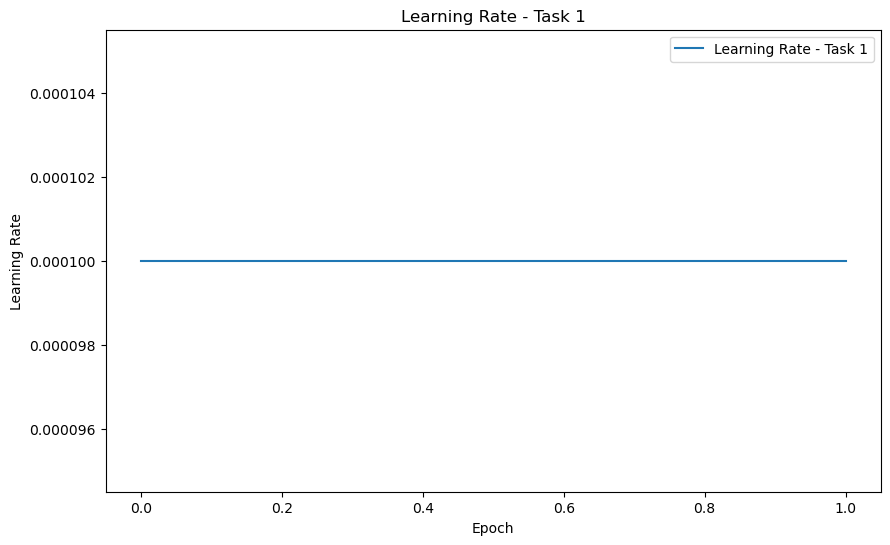

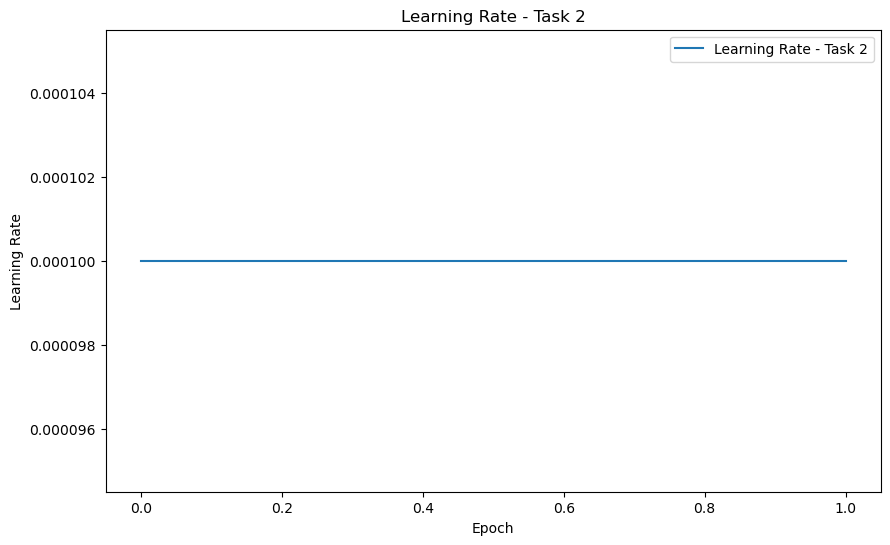

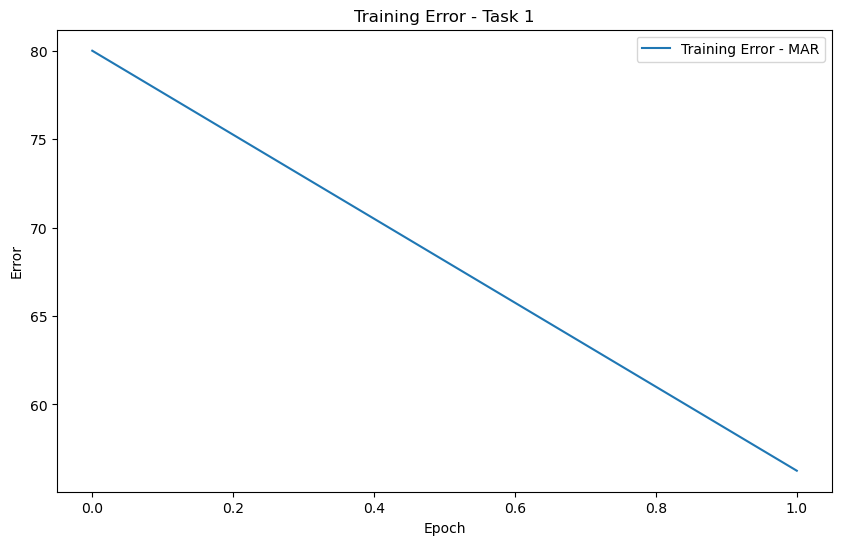

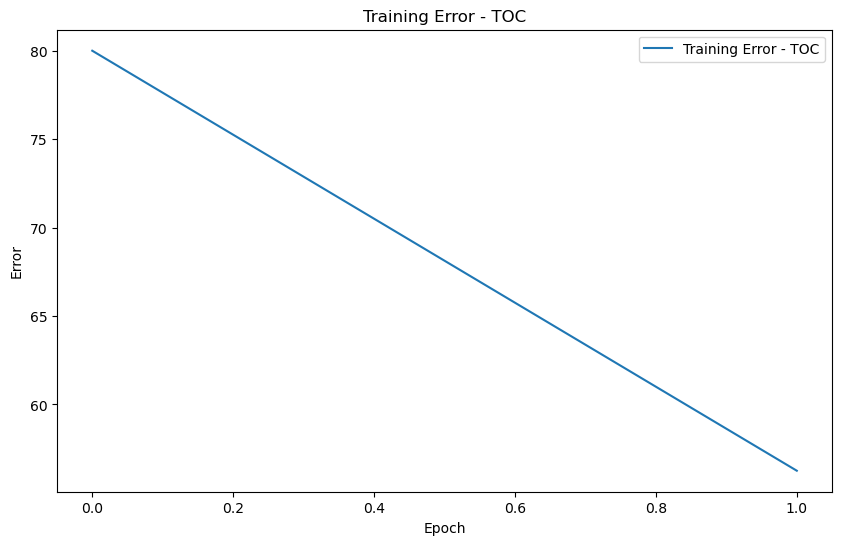

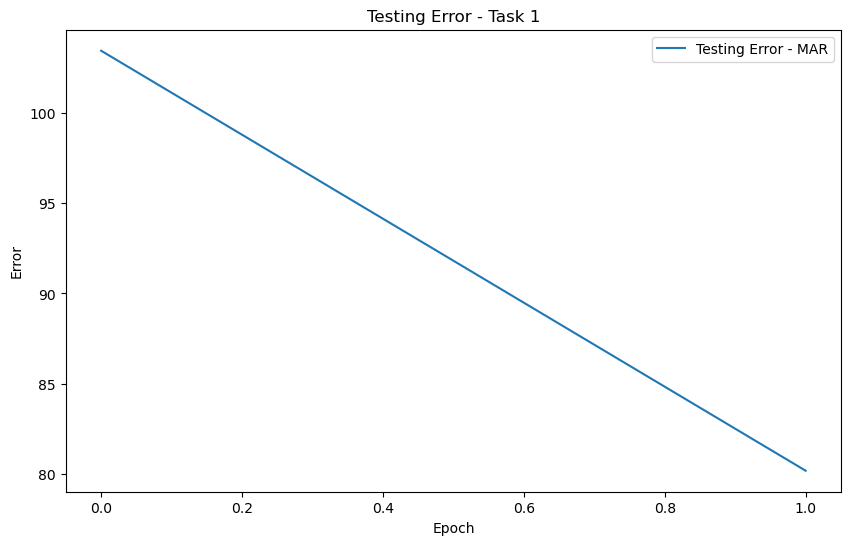

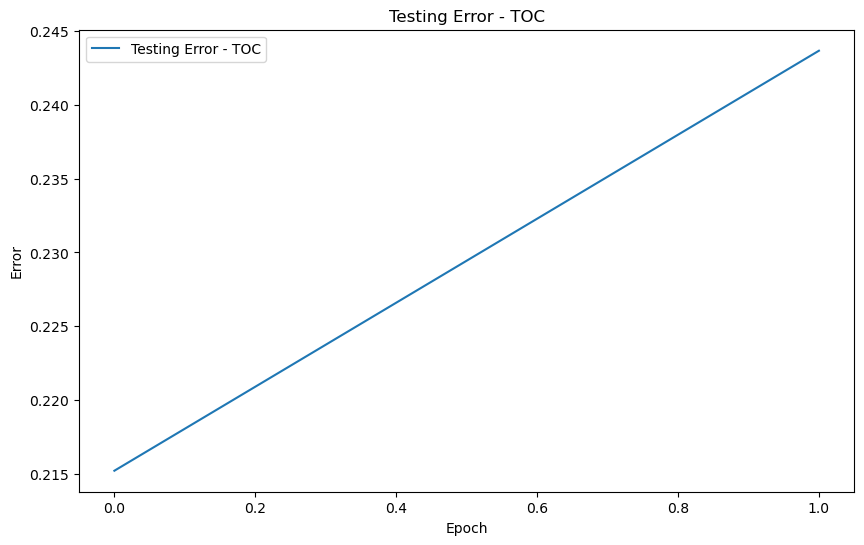

To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).


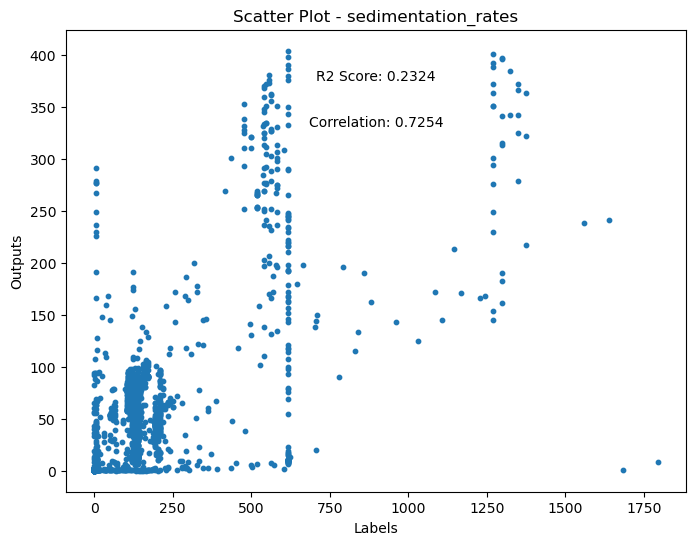

To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).


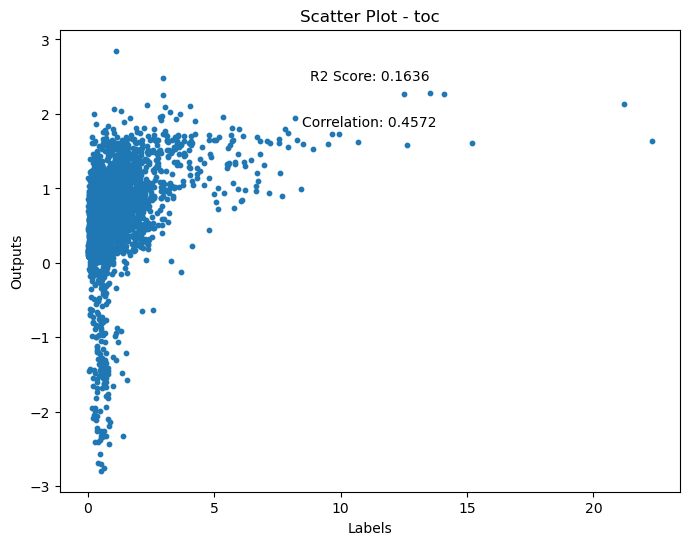

To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).



=== Training Set Results ===

Task: sedimentation_rates
MAE: 82.3303
MSE: 36600.4049
Correlation Coefficient: 0.6492
R² Score: 0.1745


To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).



Task: toc
MAE: 0.4559
MSE: 1.0424
Correlation Coefficient: 0.4638
R² Score: 0.1715

=== Test Set Results ===

Task: sedimentation_rates
MAE: 80.8038
MSE: 30435.5102
Correlation Coefficient: 0.7254
R² Score: 0.2324


To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).



Task: toc
MAE: 0.4609
MSE: 1.0471
Correlation Coefficient: 0.4572
R² Score: 0.1636


In [2]:
# %%
from sklearn.metrics import r2_score        
# Plotting the learning rate for each task
plt.figure(figsize=(10, 6))
plt.plot(learning_rate, label='Learning Rate - Task 1')
plt.xlabel('Epoch')
plt.ylabel('Learning Rate')
plt.title('Learning Rate - Task 1')
plt.legend()
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(learning_rate, label='Learning Rate - Task 2')
plt.xlabel('Epoch')
plt.ylabel('Learning Rate')
plt.title('Learning Rate - Task 2')
plt.legend()
plt.show()

# Plotting the train errors for each task
plt.figure(figsize=(10, 6))
training_losses_mar = [training_loss['sedimentation_rates'] for training_loss in training_losses]
plt.plot(training_losses_mar, label='Training Error - MAR')
plt.xlabel('Epoch')
plt.ylabel('Error')
plt.title('Training Error - Task 1')
plt.legend()
plt.show()

plt.figure(figsize=(10, 6))
training_losses_toc = [training_loss['sedimentation_rates'] for training_loss in training_losses]
plt.plot(training_losses_toc, label='Training Error - TOC')
plt.xlabel('Epoch')
plt.ylabel('Error')
plt.title('Training Error - TOC')
plt.legend()
plt.show()

# Plotting the test errors for each task
plt.figure(figsize=(10, 6))
testing_losses_mar = [testing_loss['sedimentation_rates'] for testing_loss in evaluation_losses]
plt.plot(testing_losses_mar, label='Testing Error - MAR')
plt.xlabel('Epoch')
plt.ylabel('Error')
plt.title('Testing Error - Task 1')
plt.legend()
plt.show()

plt.figure(figsize=(10, 6))
testing_losses_toc = [testing_loss['toc'] for testing_loss in evaluation_losses]
plt.plot(testing_losses_toc, label='Testing Error - TOC')
plt.xlabel('Epoch')
plt.ylabel('Error')
plt.title('Testing Error - TOC')
plt.legend()
plt.show()

for task in test_dataloaders:
    features_list = []
    labels_list = []
    for features, labels in test_dataloaders[task]:
        features = torch.tensor(features).to(device)
        features = features.to(dtype=torch.double)
        labels = torch.tensor(labels).to(device)
        labels = labels.to(dtype=torch.double)
        features_list.append(features)
        labels_list.append(labels)
    # After the loop, concatenate all features and labels
    features = torch.cat(features_list, dim=0)
    labels = torch.cat(labels_list, dim=0)
    decoded, outputs = model(features, task)
    labels = labels.reshape(-1)  # Reshape labels to match outputs
    labels = labels.cpu().detach().numpy()

    if task == "sedimentation_rates":
        outputs = outputs.cpu().detach().numpy().reshape(-1)  # Reshape outputs to match labels
    else:
        outputs = outputs.cpu().detach().numpy().reshape(-1)  # Reshape outputs to match labels
    #labels = labels.cpu().detach().numpy().reshape(-1)
    mae = mean_absolute_error(labels, outputs)
    mse = mean_squared_error(labels, outputs)
    rmse = np.sqrt(mean_squared_error(labels, outputs))


    # Calculate R2 score and correlation coefficient
    r2 = r2_score(labels, outputs)

    correlation = np.corrcoef(labels, outputs)[0, 1]

    # Create scatter plot of labels vs outputs
    plt.figure(figsize=(8, 6))
    plt.scatter(labels, outputs, s=10)
    plt.xlabel("Labels")
    plt.ylabel("Outputs")
    plt.title(f"Scatter Plot - {task}")
    plt.text(0.5, 0.9, f"R2 Score: {r2:.4f}", ha='center', va='center', transform=plt.gca().transAxes)
    plt.text(0.5, 0.8, f"Correlation: {correlation:.4f}", ha='center', va='center', transform=plt.gca().transAxes)
    plt.show()


# %%

# Evaluate both training and test results
print("\n=== Training Set Results ===")
for task in train_dataloaders:
    mae, mse, corr, r2 = evaluate_model(model, train_dataloaders[task], task, device)
    print(f"\nTask: {task}")
    print(f"MAE: {mae:.4f}")
    print(f"MSE: {mse:.4f}")
    print(f"Correlation Coefficient: {corr:.4f}")
    print(f"R² Score: {r2:.4f}")

print("\n=== Test Set Results ===")
for task in test_dataloaders:
    mae, mse, corr, r2 = evaluate_model(model, test_dataloaders[task], task, device)
    print(f"\nTask: {task}")
    print(f"MAE: {mae:.4f}")
    print(f"MSE: {mse:.4f}")
    print(f"Correlation Coefficient: {corr:.4f}")
    print(f"R² Score: {r2:.4f}")


In [2]:
import shap
import pandas as pd
import torch
import numpy as np
import pickle
import matplotlib.pyplot as plt
from tqdm import tqdm
import os

def explain_shap(model, features, task_id="sedimentation_rates",
                     feature_names=None, explainer_path='explainer.pkl',
                     shap_values_path='shap_values.pkl',
                     force_plot_index=0, summary_max_display=10,
                     output_path='shap_summary_plot.png'):
    # ✅ Wrap the model for the specific task
    class TaskWrapper(torch.nn.Module):
        def __init__(self, mtl_model, task_id):
            super().__init__()
            self.mtl_model = mtl_model
            self.task_id = task_id
        def forward(self, x):
            _, task_output = self.mtl_model(x, task_id=self.task_id)
            return task_output
    
    wrapped_model = TaskWrapper(model, task_id)
    wrapped_model.eval()
    
    # Convert the input features to a PyTorch tensor with the correct data type
    features_tensor = torch.tensor(features, dtype=torch.float64)
    
    if torch.cuda.is_available():
        wrapped_model = wrapped_model.cuda()
        features_tensor = features_tensor.cuda()
    
    # ✅ Create the SHAP DeepExplainer for the single-task wrapper
    print(f"Creating SHAP explainer for task: {task_id}")
    background = features_tensor[:min(100, len(features_tensor))]  # subset for efficiency
    explainer = shap.DeepExplainer(wrapped_model, background)
    
    # Calculate SHAP values with progress tracking
    print(f"Calculating SHAP values for {len(features_tensor)} samples...")
    
    # Option 1: Batch processing with progress bar
    batch_size = 5000  # Adjust based on your memory constraints
    shap_values_list = []
    
    num_batches = (len(features_tensor) + batch_size - 1) // batch_size
    
    with tqdm(total=len(features_tensor), desc="Computing SHAP values") as pbar:
        for i in range(0, len(features_tensor), batch_size):
            batch = features_tensor[i:i + batch_size]
            batch_shap_values = explainer.shap_values(batch)
            
            # Handle list output (multiple output dimensions)
            if isinstance(batch_shap_values, list):
                batch_shap_values = batch_shap_values[0]
            
            shap_values_list.append(batch_shap_values)
            pbar.update(len(batch))
    
    # Concatenate all batch results
    shap_values = np.concatenate(shap_values_list, axis=0)
    
    shap.initjs()
    features_np = features_tensor.cpu().detach().numpy()
    
    """
    # Save SHAP explainer and values
    with open(explainer_path, 'wb') as f:
        pickle.dump(explainer, f)
    with open(shap_values_path, 'wb') as f:
        pickle.dump(shap_values, f)
    """
    
    # Create a summary plot
    print("Generating SHAP summary plot...")
    plt.figure(dpi=300)
    shap.summary_plot(shap_values, features_np, max_display=summary_max_display, show=False)
    print(f"SHAP values shape: {shap_values.shape}")
    print(f"SHAP values statistics - Min: {shap_values.min():.4f}, Max: {shap_values.max():.4f}, Mean: {shap_values.mean():.4f}")
    
    # Save SHAP values as a numpy array
    shap_output_path = str(output_path).replace('.png', '_shap_values.npy')
    np.save(shap_output_path, shap_values)
    print(f"SHAP values saved to: {shap_output_path}")
    
    plt.savefig(output_path, bbox_inches='tight', dpi=300)
    print(f"✅ SHAP analysis complete for task: {task_id}")
    print(f"Plot saved to: {output_path}")
    
    return shap_values


# Path to the saved SHAP values numpy file
shap_values_path = "shap_summary_plot_DO_MAR_masked_shap_values_DO.npy"

# Load the SHAP values
if not os.path.exists(shap_values_path):
    raise FileNotFoundError(f"SHAP values file not found: {shap_values_path}")

shap_values = np.load(shap_values_path)

print(f"Loaded SHAP values: shape={shap_values.shape}")
print(f"Summary Statistics: min={shap_values.min():.4f}, max={shap_values.max():.4f}, mean={shap_values.mean():.4f}")

# For beeswarm plot, you typically need the original feature values too
features_path = "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/worldfeatures/WorldFeaturesAllnoNaN_SedTOC_explain/Sed_world_feature_000.npy"
features = np.load(features_path)
features_full = features.reshape([2160, 4320, 110])
features_masked = np.copy(features_full)
features_masked_flat = features_masked.reshape(features_masked.shape[0] * features_masked.shape[1], features_masked.shape[2])
mask = ~np.isnan(features_masked_flat).any(axis=1)
features_masked_flat_clean = features_masked_flat[mask]

# Optionally, add feature_names if you have them, for nicer plots
feature_names = None  # Replace with a list of 110 feature names if available

import shap
import pandas as pd
shap.initjs()
"""
# Use SHAP's summary_plot with plot_type="beeswarm"
plt.figure(figsize=(20, 8))
shap.summary_plot(
    shap_values, 
    features_masked_flat_clean, 
    feature_names=feature_names, 
    max_display=30,  # You can set this as desired
    plot_type="dot"  # "dot" is the default: beeswarm plot
)
plt.tight_layout()
plt.show()
"""

# Also show a dataframe with feature indices and their mean(|shap_value|)
mean_abs_shap = np.mean(np.abs(shap_values), axis=0)
df_shap = pd.DataFrame({
    "feature_number": range(len(mean_abs_shap)),
    "mean_abs_shap_value": mean_abs_shap
})
# Load feature names from the file called 'feature_names'
feature_names_file = "feature_names"

feature_names_list = []
with open(feature_names_file, "r") as f:
    for line in f:
        line = line.strip()
        if line:  # ignore blank lines
            feature_names_list.append(line)

# Pad or truncate to expected length (110)
if len(feature_names_list) >= 110:
    feature_names_list = feature_names_list[:110]
else:
    feature_names_list += [f"feature_{i}" for i in range(len(feature_names_list), 110)]

df_shap["feature_name"] = df_shap["feature_number"].apply(lambda x: feature_names_list[x] if x < len(feature_names_list) else f"feature_{x}")

top10 = df_shap.sort_values(by="mean_abs_shap_value", ascending=False).head(10)
print(top10[["feature_number", "feature_name", "mean_abs_shap_value"]])

Loaded SHAP values: shape=(5584087, 110)
Summary Statistics: min=-215.4777, max=278.5149, mean=0.0235


     feature_number                                       feature_name  \
108             108                      probabilities_Dia.Ooze_mod.nc   
106             106                      probabilities_Calc.Sed_mod.nc   
109             109                      probabilities_Lith.Sed_mod.nc   
6                 6  GL_COMPACT_ALL_SND_ISOPACH_SED_THICK_M_GLOBSED...   
32               32                           SEAFLOOR_DENSITY_GCM3.nc   
5                 5  GL_COMPACT_ALL_CLY_ISOPACH_SED_THICK_M_GLOBSED...   
107             107                          probabilities_Clay_mod.nc   
77               77                                  SS_CORIOLIS.5m.nc   
1                 1           EOT20_tidal_ratio_5arcmin_interp_land.nc   
26               26           GL_TOT_SED_THICK_M_GLOBSED_Straume.5m.nc   

     mean_abs_shap_value  
108             0.417791  
106             0.211584  
109             0.204041  
6               0.202302  
32              0.171007  
5               0.16878

In [26]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

def violin_beeswarm_plot(
    shap_values_path,
    features_path,
    feature_names_file=None,
    max_display=10,  # only top 10
    save_path=None,
    figsize=(16, 8),
    top=True,
    test_n=200  # number of samples to take for test, default 200
):
    """
    Custom beeswarm-like plot with scatter points colored by feature value, similar to SHAP beeswarm.

    Parameters
    ----------
    shap_values_path : str
        Path to numpy file of SHAP values (shape: [n_samples, n_features])
    features_path : str
        Path to numpy file of features (shape: [flat or needs reshaping, 110])
    feature_names_file : str, optional
        Path to text file with feature names (one per line), matches order in features/SHAP arrays.
    max_display : int
        How many features to show (top-N by mean(|SHAP|)).
    save_path : str, optional
        If given, figure is saved to this file path.
    figsize : tuple
        Matplotlib figsize for the plot.
    top : bool
        If True, show top max_display features by mean(|SHAP|).
    test_n : int
        Number of rows to take for testing from shap values and features.
    """
    # Load SHAP values
    if not os.path.exists(shap_values_path):
        raise FileNotFoundError(f"SHAP values file not found: {shap_values_path}")
    shap_values = np.load(shap_values_path)
    print(f"Loaded SHAP values: shape={shap_values.shape}")

    # Take only a subsection for testing
    n_keep = min(test_n, shap_values.shape[0])
    shap_values = shap_values[:n_keep, :]
    print(f"Using only first {n_keep} SHAP samples for test.")

    # Load and flatten features
    features = np.load(features_path)
    if features.ndim == 1 or features.shape[-1] != shap_values.shape[1]:
        features = features.reshape((-1, shap_values.shape[1]))
    features = features[:n_keep, :]
    print(f"Using only first {n_keep} feature samples for test.")

    # Features (for color-coding) may contain nans--mask these rows out for plotting points
    mask = ~np.isnan(features).any(axis=1)
    features_clean = features[mask]
    shap_values_clean = shap_values[mask]
    print(f"After cleaning nans: features {features_clean.shape}, shap {shap_values_clean.shape}")

    # Load feature names, if available
    if feature_names_file is not None and os.path.exists(feature_names_file):
        feature_names_list = []
        with open(feature_names_file, "r") as f:
            for line in f:
                line = line.strip()
                if line:
                    feature_names_list.append(line)
        feat_n = shap_values.shape[1]
        if len(feature_names_list) >= feat_n:
            feature_names_list = feature_names_list[:feat_n]
        else:
            feature_names_list += [f"feature_{i}" for i in range(len(feature_names_list), feat_n)]
    else:
        feature_names_list = [f"feature_{i}" for i in range(shap_values.shape[1])]

    # Rank features by mean(|shap|)
    mean_abs_shap = np.abs(shap_values_clean).mean(axis=0)
    feat_order = np.argsort(mean_abs_shap)[::-1] if top else np.arange(len(mean_abs_shap))
    top_feats = feat_order[:max_display]

    # Prepare for beeswarm scatter: plot each sample along x=shap, y=row for each feature, color by feature value.
    plt.figure(figsize=figsize)
    cmap = plt.get_cmap("coolwarm")
    norm = plt.Normalize(vmin=np.nanmin(features_clean[:, top_feats]), vmax=np.nanmax(features_clean[:, top_feats]))
    
    y_ticks = []
    y_labels = []
    for i, feat_idx in enumerate(top_feats):
        # Vertical stacking: beeswarm "y" is i+1 for each feature.
        y_pos = np.full(shap_values_clean.shape[0], i + 1)
        # Order samples within feature so points don't overlap: sort shap, jitter a bit
        order = np.argsort(shap_values_clean[:, feat_idx])
        # Colored by feature value
        feat_val = features_clean[:, feat_idx]
        sc = plt.scatter(
            shap_values_clean[order, feat_idx],
            y_pos[order] + 0.13 * (np.random.rand(len(order)) - 0.5),
            c=feat_val[order],
            cmap=cmap,
            norm=norm,
            s=24,
            edgecolors="none",
            alpha=0.8
        )
        y_ticks.append(i + 1)
        y_labels.append(feature_names_list[feat_idx])

    cbar = plt.colorbar(sc, orientation="vertical", pad=0.02)
    cbar.set_label("Feature Value")

    plt.yticks(y_ticks, labels=y_labels)
    plt.xlabel("SHAP Value")
    plt.ylabel("Feature")
    plt.title("Custom Beeswarm Plot (Top 10 SHAP Features, Colored by Value, Test Section)")
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, bbox_inches="tight", dpi=300)
        print(f"Plot saved to {save_path}")
    plt.show()

    # Also print top features dataframe for reference
    df_shap = pd.DataFrame({
        "feature_number": range(len(mean_abs_shap)),
        "mean_abs_shap_value": mean_abs_shap,
        "feature_name": feature_names_list
    })
    print(df_shap.iloc[top_feats][["feature_number", "feature_name", "mean_abs_shap_value"]])

# Example usage:
violin_beeswarm_plot(
    shap_values_path="shap_summary_plot_entire_MAR_masked_shap_values.npy",
    features_path="/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/worldfeatures/WorldFeaturesAllnoNaN_SedTOC_explain/Sed_world_feature_000.npy",
    feature_names_file="feature_names",
    max_display=10,
    save_path=None,  # or "my_beeswarm_top10_colored.png"
    figsize=(20, 10),
    top=True,
    test_n=200   # Only test with first 200 rows
)

Loaded SHAP values: shape=(6149651, 110)
Using only first 200 SHAP samples for test.
Using only first 200 feature samples for test.
After cleaning nans: features (0, 110), shap (0, 110)


Mean of empty slice.


ValueError: zero-size array to reduction operation fmin which has no identity

<Figure size 2000x1000 with 0 Axes>

In [13]:
# In[ ]:


# In[ ]:
#model = FEA(layer_widths)
# %%
features = np.load("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/worldfeatures/WorldFeaturesAllnoNaN_SedTOC_explain/Sed_world_feature_000.npy")

print(features.shape)

# Deep ocean mask
mask_deepocean = np.load(Path().resolve().parents[1] / "data" / "interim" / "masks" / "mask_deepocean.npy")
#mask_deepocean = np.rot90(np.rot90(np.fliplr(mask_deepocean)))

# Continental shelves mask (inverse of deep ocean)
mask_continentalshelves = np.load(Path().resolve().parents[1] / "data" / "interim" / "masks" / "mask_continentalshelves.npy")
#mask_continentalshelves = np.rot90(np.rot90(np.fliplr(mask_continentalshelves)))

mask_deepocean = mask_deepocean[::1, ::1]
mask_continentalshelves = mask_continentalshelves[::1, ::1]

# Remove rows with nan values
features_full = features.reshape([2160, 4320, 110])
features_masked = np.copy(features_full)
#features_masked[np.isnan(mask_continentalshelves)] = np.nan

(9331200, 110)


In [5]:
class SedimentationRateWrapper(torch.nn.Module):
    def __init__(self, mtl_model):
        super().__init__()
        self.mtl_model = mtl_model

    def forward(self, x):
        # forward pass for the sedimentation rate head only
        _, task_output = self.mtl_model(x, task_id="sedimentation_rates")
        return task_output

flattened_size = features_masked.shape[0] * features_masked.shape[1]
features_masked_flat = features_masked.reshape(flattened_size, features_masked.shape[-1])

mask = ~np.isnan(features_masked_flat).any(axis=1)
features_masked_flat_clean = features_masked_flat[mask]



nanmax_val = np.nanmax(features_masked_flat_clean)
nanmax_indices = np.argwhere(features_masked_flat_clean == nanmax_val)
print("np.nanmax(features_masked_flat_clean):", nanmax_val)
print("First few indices where nanmax occurs:", nanmax_indices[:5])

features_masked_flat_clean_normal = (features_masked_flat_clean - X_mean) / X_std


# Find rows with and without NaN values
#nan_mask = np.isnan(features).any(axis=1)
#features_no_nan = features[~nan_mask]
#features_with_nan = features[nan_mask]
#features_masked_flat_clean_normal = features_masked_flat_clean_normal[:100,:]
features_masked_flat_clean = torch.tensor(features_masked_flat_clean).to(device)
features_masked_flat_clean = features_masked_flat_clean.to(dtype=torch.double)


# Path to the saved SHAP values numpy file
shap_values_path = "shap_summary_plot_entire_MAR_masked_shap_values.npy"

# Load the SHAP values
if not os.path.exists(shap_values_path):
    raise FileNotFoundError(f"SHAP values file not found: {shap_values_path}")

shap_values = np.load(shap_values_path)

print(f"Loaded SHAP values: shape={shap_values.shape}")
print(f"Summary Statistics: min={shap_values.min():.4f}, max={shap_values.max():.4f}, mean={shap_values.mean():.4f}")

# If the SHAP values are shape (samples, features), plot their distribution
if shap_values.ndim == 2:
    # Plot distribution histogram for flattened SHAP values
    plt.figure(figsize=(10,6))
    plt.hist(shap_values.flatten(), bins=100, color='dodgerblue', alpha=0.75)
    plt.xlabel("SHAP value")
    plt.ylabel("Frequency")
    plt.title("Distribution of SHAP values (all features, all samples)")
    plt.grid(True, linestyle='--', alpha=0.4)
    plt.tight_layout()
    plt.show()

    # Plot mean absolute SHAP value per feature
    mean_abs_shap = np.mean(np.abs(shap_values), axis=0)
    plt.figure(figsize=(14,6))
    plt.bar(range(len(mean_abs_shap)), mean_abs_shap)
    plt.xlabel("Feature Index")
    plt.ylabel("Mean(|SHAP value|)")
    plt.title("Mean Absolute SHAP Value Per Feature")
    plt.tight_layout()
    plt.show()

elif shap_values.ndim == 3:
    # Shape (samples, features, outputs)
    mean_abs_shap = np.mean(np.abs(shap_values), axis=0)
    for out in range(mean_abs_shap.shape[1]):
        plt.figure(figsize=(14,6))
        plt.bar(range(mean_abs_shap.shape[0]), mean_abs_shap[:, out])
        plt.xlabel("Feature Index")
        plt.ylabel(f"Mean(|SHAP value|) (output {out})")
        plt.title(f"Mean Absolute SHAP Value Per Feature (output {out})")
        plt.tight_layout()
        plt.show()
else:
    print(f"Unexpected SHAP values shape: {shap_values.shape}")

NameError: name 'features_masked' is not defined

In [ ]:


# GPU intensive operation!!!
explain_shap(model, features_masked_flat_clean_normal, feature_names=None, explainer_path='preprocessed/explainer_entire_MAR.pkl', shap_values_path='preprocessed/shap_values_entire_MAR.pkl', force_plot_index=0, summary_max_display=10, output_path='shap_summary_plot_entire_MAR_masked.png')


Creating SHAP explainer for task: sedimentation_rates
Calculating SHAP values for 6149651 samples...


Computing SHAP values:   8%|▋       | 515000/6149651 [24:51<4:29:48, 348.06it/s]

In [9]:
def explain_shap(model, features, task_id="sedimentation_rates",
                     feature_names=None, explainer_path='explainer.pkl',
                     shap_values_path='shap_values.pkl',
                     force_plot_index=0, summary_max_display=10,
                     output_path='shap_summary_plot.png'):

    # ✅ Wrap the model for the specific task
    class TaskWrapper(torch.nn.Module):
        def __init__(self, mtl_model, task_id):
            super().__init__()
            self.mtl_model = mtl_model
            self.task_id = task_id

        def forward(self, x):
            _, task_output = self.mtl_model(x, task_id=self.task_id)
            return task_output

    # Wrap the MTL model for a specific task
    wrapped_model = TaskWrapper(model, task_id="sedimentation_rates")
    wrapped_model.eval()
    features = features[:20,:]
    # Convert input features to numpy for Kernel SHAP
    X = features.astype(np.float64)
    
    # Select a background subset for efficiency
    background = X[:min(10, len(X))]
    """
    # Create Kernel SHAP explainer
    explainer = shap.KernelExplainer(
        lambda x: wrapped_model(torch.tensor(x, dtype=torch.float64)).detach().cpu().numpy(),
        background
    )

    # Compute SHAP values
    shap_values = explainer.shap_values(X)
    # If output is a list (e.g., one element for each output dimension)
    if isinstance(shap_values, list):
        shap_values = shap_values[0]

    shap.initjs()
    """
    # Background data as a torch tensor
    background_torch = torch.tensor(background, dtype=torch.float64)

    # Create DeepSHAP explainer
    explainer = shap.DeepExplainer(
        model,
        background_torch
    )

    # Input data as torch tensor
    X_torch = torch.tensor(X, dtype=torch.float64)

    # Compute SHAP values
    shap_values = explainer.shap_values(X_torch)

    # If output is a list (e.g., multi-output model)
    if isinstance(shap_values, list):
        shap_values = shap_values[0]

    shap.initjs()
    #features_np = features_tensor.cpu().detach().numpy()
    features_np = X

    """
    # Save SHAP explainer and values
    with open(explainer_path, 'wb') as f:
        pickle.dump(explainer, f)
    with open(shap_values_path, 'wb') as f:
        pickle.dump(shap_values, f)
    """
        # Create a summary plot
    plt.figure(dpi=300)
    shap.summary_plot(shap_values, features_np, max_display=summary_max_display, show=False)
    print(shap_values)
    # Save SHAP values as a numpy array
    np.save(str(output_path).replace('.png', '_shap_values.npy'), shap_values)
    plt.savefig(output_path, bbox_inches='tight', dpi=300)
    print(f"✅ SHAP analysis complete for task: {task_id}")
    print(f"Results saved to {output_path}")

    return shap_values

In [13]:
for task in test_dataloaders:
    features_list = []
    labels_list = []
    for features, labels in test_dataloaders[task]:
        features = torch.tensor(features).to(device)
        features = features.to(dtype=torch.double)
        labels = torch.tensor(labels).to(device)
        labels = labels.to(dtype=torch.double)
        features_list.append(features)
        labels_list.append(labels)
    # After the loop, concatenate all features and labels
    features = torch.cat(features_list, dim=0)
    labels = torch.cat(labels_list, dim=0)
    decoded, outputs = model(features, task)
    labels = labels.reshape(-1)  # Reshape labels to match outputs
    labels = labels.cpu().detach().numpy()

    if task == "sedimentation_rates":
        outputs = outputs.cpu().detach().numpy().reshape(-1)  # Reshape outputs to match labels
        print(outputs)
        print(task)

[8.22012162e+02 9.93072087e+00 9.32968390e+02 ... 5.14566572e+00
 1.31244902e+02 5.25962701e-01]
sedimentation_rates


To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).


  0%|          | 0/20 [00:00<?, ?it/s]

No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored


[[ 0.          0.06256025  0.         ... -0.00409605  0.02304135
   0.02172353]
 [ 0.         -0.005366    0.         ...  0.00773849 -0.05101536
  -0.0633695 ]
 [ 0.         -0.00919311  0.         ...  0.00703487 -0.06099743
  -0.06490962]
 ...
 [ 0.          0.03906617  0.         ... -0.01153595  0.02143454
  -0.03198923]
 [ 0.          0.01495536  0.         ... -0.00803775  0.03727694
  -0.06448718]
 [ 0.          0.06645781  0.         ... -0.01767885  0.06137708
  -0.09126289]]
✅ SHAP analysis complete for task: sedimentation_rates
Results saved to shap_summary_plot_entire_MAR_masked.png


array([[ 0.        ,  0.06256025,  0.        , ..., -0.00409605,
         0.02304135,  0.02172353],
       [ 0.        , -0.005366  ,  0.        , ...,  0.00773849,
        -0.05101536, -0.0633695 ],
       [ 0.        , -0.00919311,  0.        , ...,  0.00703487,
        -0.06099743, -0.06490962],
       ...,
       [ 0.        ,  0.03906617,  0.        , ..., -0.01153595,
         0.02143454, -0.03198923],
       [ 0.        ,  0.01495536,  0.        , ..., -0.00803775,
         0.03727694, -0.06448718],
       [ 0.        ,  0.06645781,  0.        , ..., -0.01767885,
         0.06137708, -0.09126289]])

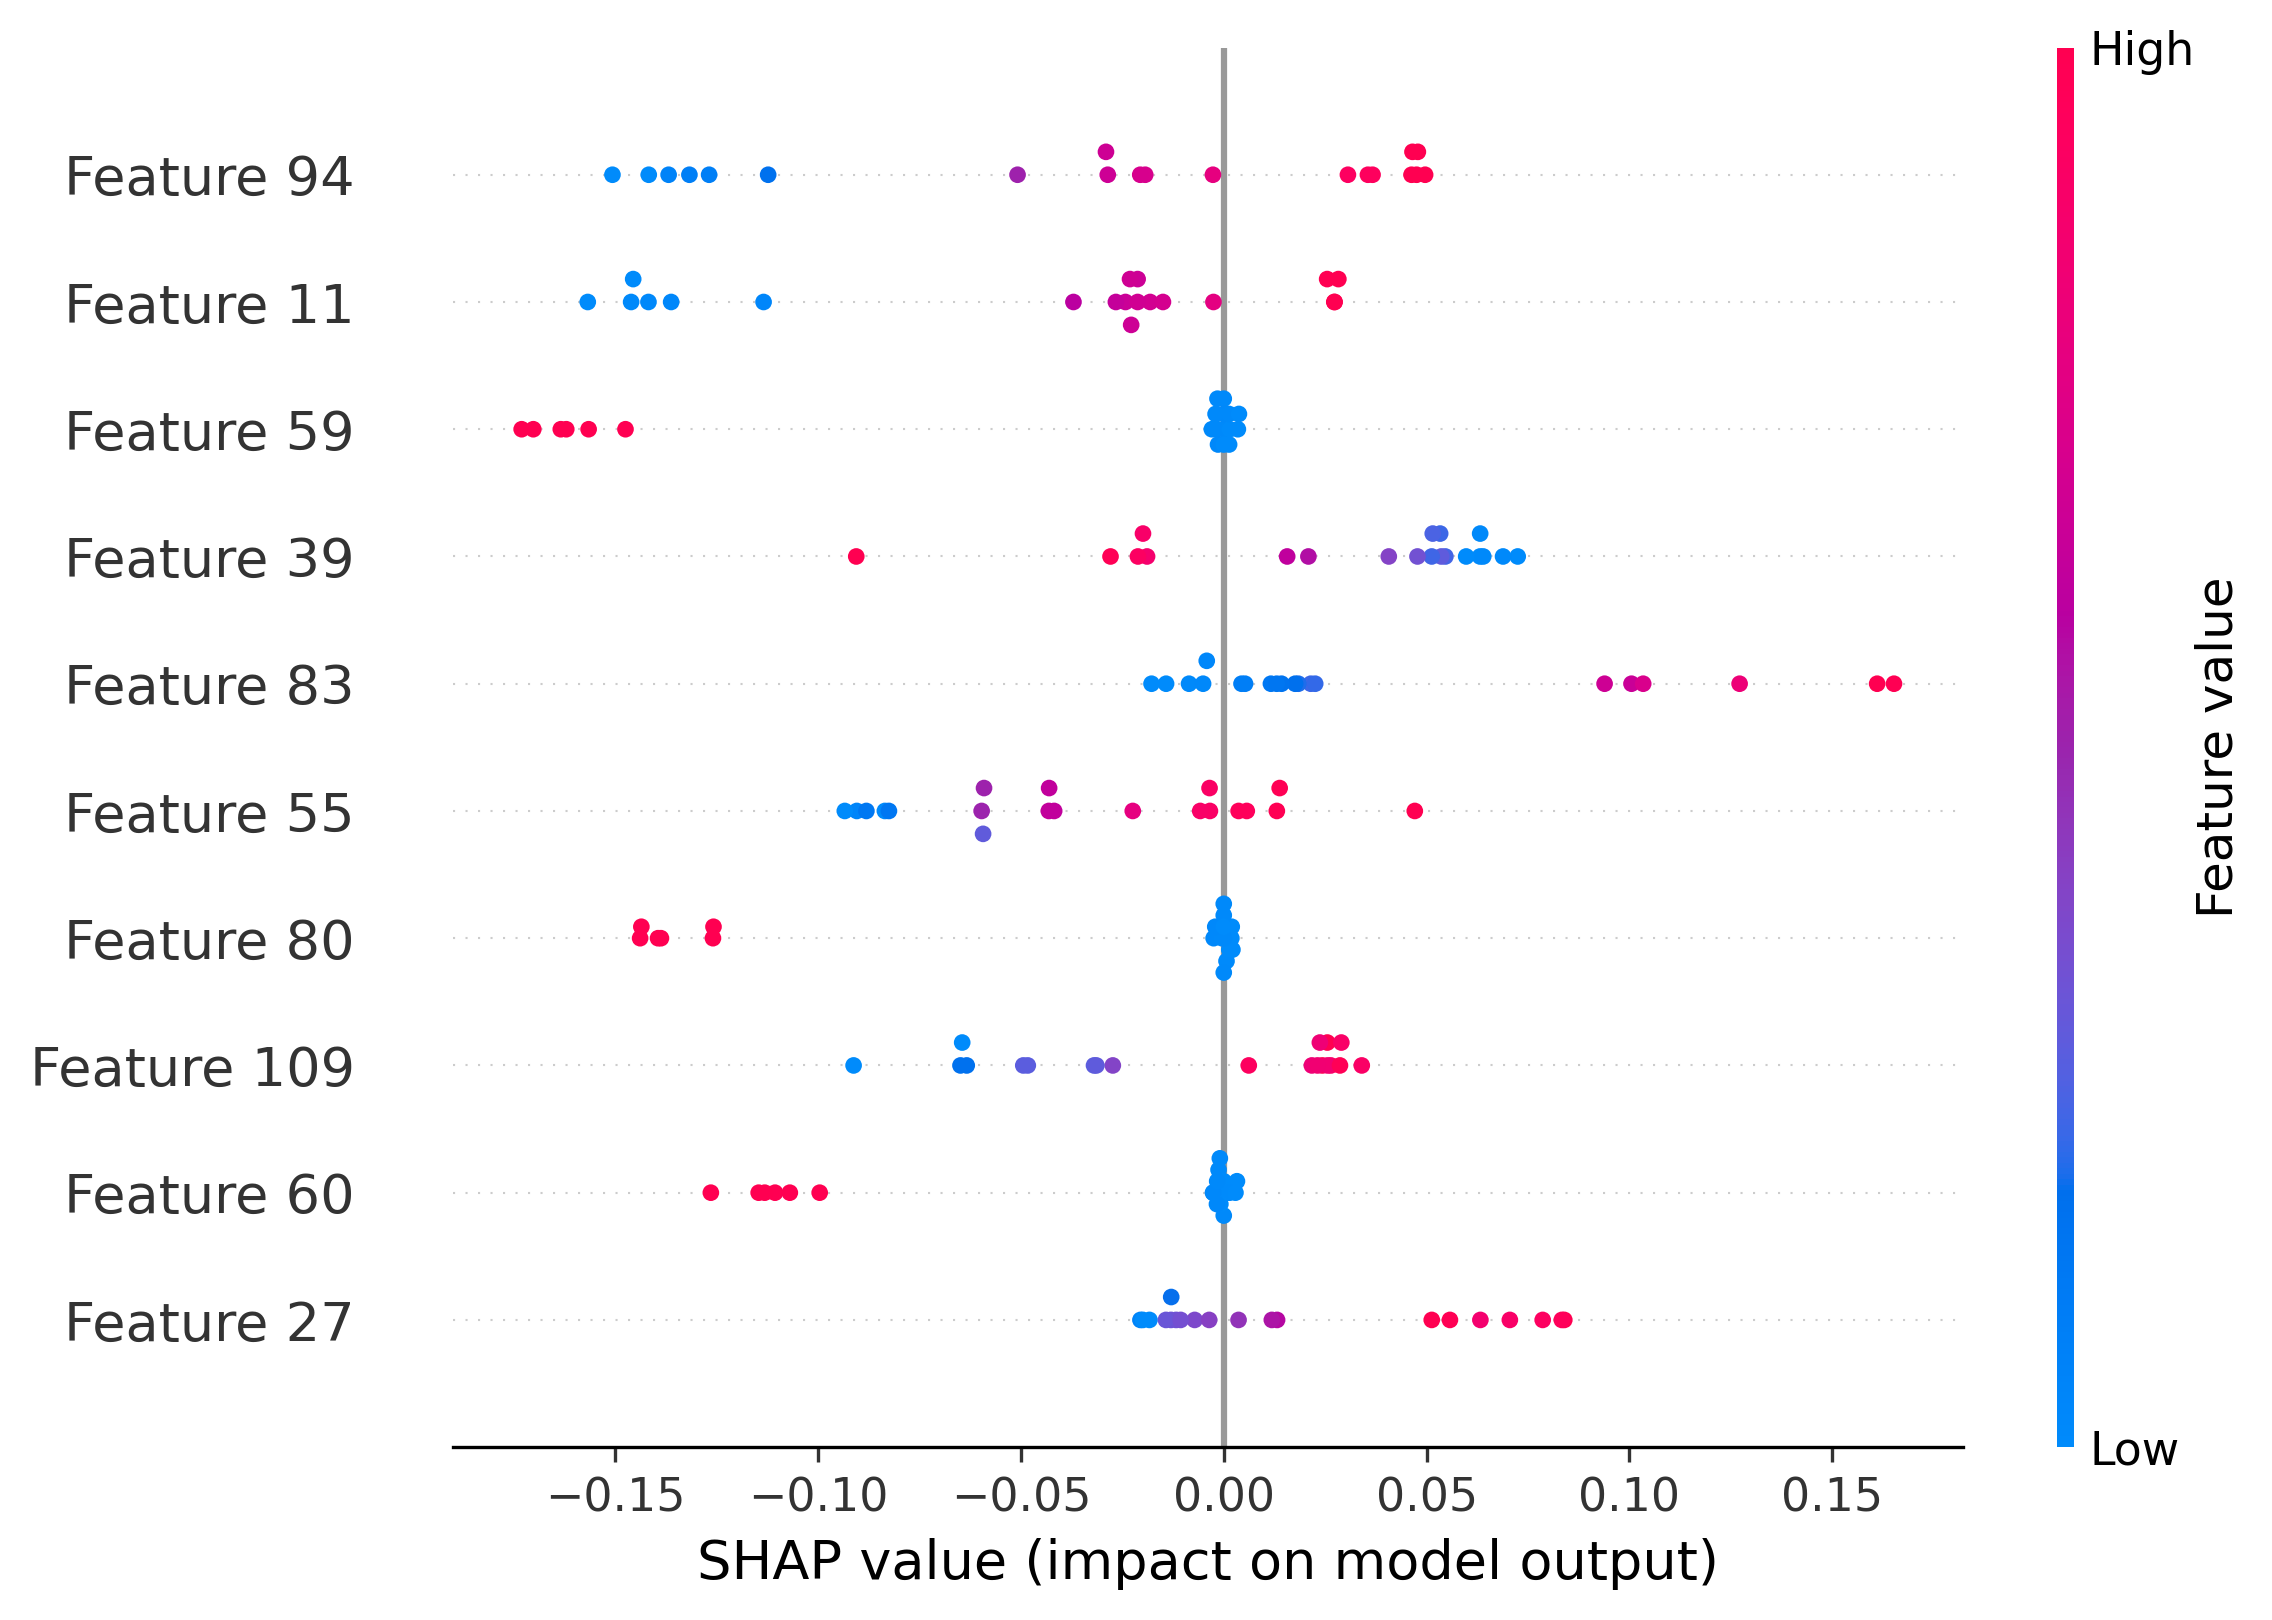

In [ ]:

# GPU intensive operation!!!
explain_shap(model, features_masked_flat_clean_normal, feature_names=None, explainer_path='preprocessed/explainer_entire_MAR.pkl', shap_values_path='preprocessed/shap_values_entire_MAR.pkl', force_plot_index=0, summary_max_display=10, output_path='shap_summary_plot_entire_MAR_masked.png')

# If the previous line has already been performed and the shap values are saved, only the following lines can be used.
#with open('preprocessed/explainer_CS_MAR_test.pkl', 'rb') as explainer_file:
#    explainer = pickle.load(explainer_file)

#with open('preprocessed/shap_values_CS_MAR_test.pkl', 'rb') as shap_values_file:
#    shap_values = pickle.load(shap_values_file)

In [ ]:
shap_values = np.load("shap_summary_plot_entire_MAR_masked_shap_values.npy")
# Create shap array for non-NaN rows
shap_array_no_nan = np.array(shap_values)
# If shap_values is a list of arrays, stack them
if isinstance(shap_array_no_nan, list):
    shap_array_no_nan = np.stack(shap_array_no_nan, axis=0)

# Now, create a full shap_array with NaN rows inserted at the correct positions
full_shap_array = np.full((features.shape[0], shap_array_no_nan.shape[1]), np.nan)
full_shap_array[mask] = shap_array_no_nan

# If the original code expected a 3D array, adjust accordingly
# For example, if each shap value is a vector per feature, and features.shape = (N, F)
# and shap_array_no_nan.shape = (num_valid, F)
# then full_shap_array = (N, F), which is correct

# If you need to reshape to match (num_samples, num_features, 1) or similar, do so here

shap_array = full_shap_array

# %%
print(features_masked_flat_clean.shape)
print(shap_array.shape)

# %%
shap_array = shap_array.reshape(432, 864, shap_array.shape[1])
#np.save("shap_array_MAR_entire.npy", shap_array)

ValueError: shape mismatch: value array of shape (20,110) could not be broadcast to indexing result of shape (245636,110)

In [ ]:
# Feature names for the 160 features (order must match the SHAP array)
feature_names = ['DERIVATIVE_lithology_grain_size_Everardo_global_8.nc',
 'EOT20_tidal_ratio_5arcmin_interp_land.nc',
 'EOT20_u3_5arcmin_interp_land.nc',
 'EOT20_umax_5arcmin_interp_land.nc',
 'EOT20_urms_5arcmin_interp_land.nc',
 'GL_COMPACT_ALL_CLY_ISOPACH_SED_THICK_M_GLOBSED_1_8_Straume.1d_5_arc_min_interpolated.nc',
 'GL_COMPACT_ALL_SND_ISOPACH_SED_THICK_M_GLOBSED_1_8_Straume.1d_5_arc_min_interpolated.nc',
 'GL_DIST_TO_COAST_KM_ETOPO.5m.grd',
 'GL_DIST_TO_COAST_KM_ETOPO.r50km.men.5m.grd',
 'GL_ELEVATION_M_ASL_ETOPO2v2.5m.grd',
 'GL_ELEVATION_M_ASL_ETOPO2v2.r50km.men.5m.grd',
 'GL_HEATFLUX_MWM2_Becker.5m.nc',
 'GL_HEATFLUX_MWM2_Becker_r50km_men.nc',
 'GL_RIVERMOUTH_CO2_TGCYR-1_ORNL.5m.grd',
 'GL_RIVERMOUTH_CO2_TGCYR-1_ORNL.r50km.men.5m.grd',
 'GL_RIVERMOUTH_DOC_TGCYR-1_ORNL.5m.grd',
 'GL_RIVERMOUTH_DOC_TGCYR-1_ORNL.r50km.men.5m.grd',
 'GL_RIVERMOUTH_HCO3_TGCYR-1_ORNL.5m.grd',
 'GL_RIVERMOUTH_HCO3_TGCYR-1_ORNL.r50km.men.5m.grd',
 'GL_RIVERMOUTH_POC_TGCYR-1_ORNL.5m.grd',
 'GL_RIVERMOUTH_POC_TGCYR-1_ORNL.r50km.men.5m.grd',
 'GL_RIVERMOUTH_TSS_TGYR-1_ORNL.5m.grd',
 'GL_RIVERMOUTH_TSS_TGYR-1_ORNL.r125km.men.5m.grd',
 'GL_RIVERMOUTH_TSS_TGYR-1_ORNL.r50km.men.5m.grd',
 'GL_SC_THICKNESS_PER_AGE.nc',
 'GL_SC_THICKNESS_PER_AGE_r50km.nc',
 'GL_TOT_SED_THICK_M_GLOBSED_Straume.5m.nc',
 'GL_TOT_SED_THICK_M_GLOBSED_Straume_r50km.5m.nc',
 'ISOPACH_0_1.8_METERS_KNNPREDICTION.5m.nc',
 'ISOPACH_0_1.8_METERS_KNNPREDICTION_r50km_men.nc',
 'SC_CRUST_AGE_MA_Muller.5m.nc',
 'SC_CRUST_AGE_MA_Muller.5m_r50km.nc',
 'SEAFLOOR_DENSITY_GCM3.nc',
 'SEAFLOOR_DENSITY_GCM3_r50km_men.nc',
 'SF_AVG_SEA_DENSITY_KGM3_DECADAL_MEAN_woa13x.5m.grd',
 'SF_AVG_SEA_DENSITY_KGM3_DECADAL_MEAN_woa13x.r50km.men.5m.grd',
 'SF_CURRENT_EAST_MS_2012_12_HYCOMx.5m.grd',
 'SF_CURRENT_EAST_MS_2012_12_HYCOMx.r50km.men.5m.grd',
 'SF_CURRENT_MAG_MS_2012_12_HYCOMx.5m.grd',
 'SF_CURRENT_MAG_MS_2012_12_HYCOMx.r50km.men.5m.grd',
 'SF_CURRENT_NORTH_MS_2012_12_HYCOMx.5m.grd',
 'SF_CURRENT_NORTH_MS_2012_12_HYCOMx.r50km.men.5m.grd',
 'SF_GRAINSIZE_D16_MM_NGDC.5m.nc',
 'SF_GRAINSIZE_D50_MM_NGDC.5m.nc',
 'SF_POROSITY_FRC.5m_with_coords_flip.nc',
 'SF_POROSITY_FRC_r50km_men.nc',
 'SF_SEA_BULKMODULUS_MPA_DECADAL_MEAN_woa13x.5m.nc',
 'SF_SEA_CONDUCTIVITY_SM_DECADAL_MEAN_woa13v2x.5m.grd',
 'SF_SEA_CONDUCTIVITY_SM_DECADAL_MEAN_woa13v2x.r50km.men.5m.grd',
 'SF_SEA_OXYGEN_MLL_DECADAL_MEAN_woa13v2x.5m.grd',
 'SF_SEA_OXYGEN_MLL_DECADAL_MEAN_woa13v2x.r50km.men.5m.grd',
 'SF_SEA_OXYGEN_PCTSAT_DECADAL_MEAN_woa13v2x.5m.grd',
 'SF_SEA_OXYGEN_PCTSAT_DECADAL_MEAN_woa13v2x.r50km.men.5m.grd',
 'SF_SEA_PRESSURE_MPA_DECADAL_MEAN_woa13x.5m.nc',
 'SF_SEA_SALINITY_PSU_DECADAL_MEAN_woa13v2x.5m.nc',
 'SF_SEA_SEA_OXYGEN_UTILIZATION_MOLM3_DECADAL_MEAN_woa13v2x.5m.grd',
 'SF_SEA_SEA_OXYGEN_UTILIZATION_MOLM3_DECADAL_MEAN_woa13v2x.r50km.men.5m.grd',
 'SF_SEA_TEMPERATURE_C_DECADAL_MEAN_woa13v2x.5m.grd',
 'SF_SEA_TEMPERATURE_C_DECADAL_MEAN_woa13v2x.r50km.men.5m.grd',
 'SL_GEOID_M_ABOVE_WGS84_NGA_egm2008.5m.grd',
 'SL_GEOID_M_ABOVE_WGS84_NGA_egm2008.r50km.men.5m.grd',
 'SS_BIOMASS_BACTERIA_LOG10_MGCM2_WEI2010x.5m.grd',
 'SS_BIOMASS_BACTERIA_LOG10_MGCM2_WEI2010x.r50km.men.5m.grd',
 'SS_BIOMASS_FISH_LOG10_MGCM2_WEI2010x.5m.grd',
 'SS_BIOMASS_FISH_LOG10_MGCM2_WEI2010x.r50km.men.5m.grd',
 'SS_BIOMASS_INVERTEBRATE_LOG10_MGCM2_WEI2010x.5m.grd',
 'SS_BIOMASS_INVERTEBRATE_LOG10_MGCM2_WEI2010x.r50km.men.5m.grd',
 'SS_BIOMASS_MACROFAUNA_LOG10_MGCM2_WEI2010x.5m.grd',
 'SS_BIOMASS_MACROFAUNA_LOG10_MGCM2_WEI2010x.r50km.men.5m.grd',
 'SS_BIOMASS_MEGAFAUNA_LOG10_MGCM2_WEI2010x.5m.grd',
 'SS_BIOMASS_MEGAFAUNA_LOG10_MGCM2_WEI2010x.r50km.men.5m.grd',
 'SS_BIOMASS_MEIOFAUNA_LOG10_MGCM2_WEI2010x.5m.grd',
 'SS_BIOMASS_MEIOFAUNA_LOG10_MGCM2_WEI2010x.r50km.men.5m.grd',
 'SS_BIOMASS_TOTAL_LOG10_MGCM2_WEI2010x.5m.grd',
 'SS_BIOMASS_TOTAL_LOG10_MGCM2_WEI2010x.r50km.men.5m.grd',
 'SS_CHLOROPHYLL_LOG_MG_M3_MODIS_Aqua_MISSION_MEANx.5m.grd',
 'SS_CHLOROPHYLL_LOG_MG_M3_MODIS_Aqua_MISSION_MEANx.r50km.men.5m.grd',
 'SS_CORIOLIS.5m.nc',
 'SS_DENSITY_KGM-3_SACD_Aquarius_MISSION_MEANx.5m.grd',
 'SS_DENSITY_KGM-3_SACD_Aquarius_MISSION_MEANx.r50km.men.5m.grd',
 'SS_GEOID_ANOMALY_NGA_egm2008.5m.nc',
 'SS_GEOID_ANOMALY_NGA_egm2008.r50km.men.5m.nc',
 'SS_MIXED_LAYER_DEPTH_MAX_M_Goyetx.5m.grd',
 'SS_MIXED_LAYER_DEPTH_MAX_M_Goyetx.r50km.men.5m.grd',
 'SS_MIXED_LAYER_DEPTH_MIN_M_Goyetx.5m.grd',
 'SS_MIXED_LAYER_DEPTH_MIN_M_Goyetx.r50km.men.5m.grd',
 'SS_PIC_LOG_MOL_M3-1_MODIS_Aqua_MISSION_MEANx.5m.grd',
 'SS_PIC_LOG_MOL_M3-1_MODIS_Aqua_MISSION_MEANx.r50km.men.5m.grd',
 'SS_POC_LOG_MOL_M3-1_MODIS_Aqua_MISSION_MEANx.5m.grd',
 'SS_POC_LOG_MOL_M3-1_MODIS_Aqua_MISSION_MEANx.r50km.men.5m.grd',
 'SS_WAVE_DIRECTION_DEG_2012_12_WAVEWATCH3x.5m.grd',
 'SS_WAVE_DIRECTION_DEG_2012_12_WAVEWATCH3x.r50km.men.5m.grd',
 'SS_WAVE_HEIGHT_M_2012_12_WAVEWATCH3x.5m.grd',
 'SS_WAVE_HEIGHT_M_2012_12_WAVEWATCH3x.r50km.men.5m.grd',
 'SS_WAVE_PERIOD_S_2012_12_WAVEWATCH3x.5m.grd',
 'SS_WAVE_PERIOD_S_2012_12_WAVEWATCH3x.r50km.men.5m.grd',
 'SS_WINDSPEED_MS-1_SACD_Aquarius_MISSION_MEANx.5m.grd',
 'SS_WINDSPEED_MS-1_SACD_Aquarius_MISSION_MEANx.r50km.men.5m.grd',
 'TOU_Jorgenson2022.nc',
 'litho_maps_type1_.nc',
 'litho_maps_type2_.nc',
 'litho_maps_type3_.nc',
 'litho_maps_type4_.nc',
 'litho_maps_type5_.nc',
 'litho_maps_type6_.nc',
 'lithology_grain_size_Everardo_global_8.nc',
 'probabilities_Calc.Sed_mod.nc',
 'probabilities_Clay_mod.nc',
 'probabilities_Dia.Ooze_mod.nc',
 'probabilities_Lith.Sed_mod.nc']

In [ ]:
len(feature_names)

110

AssertionError: Feature and SHAP matrices must have the same number of rows!

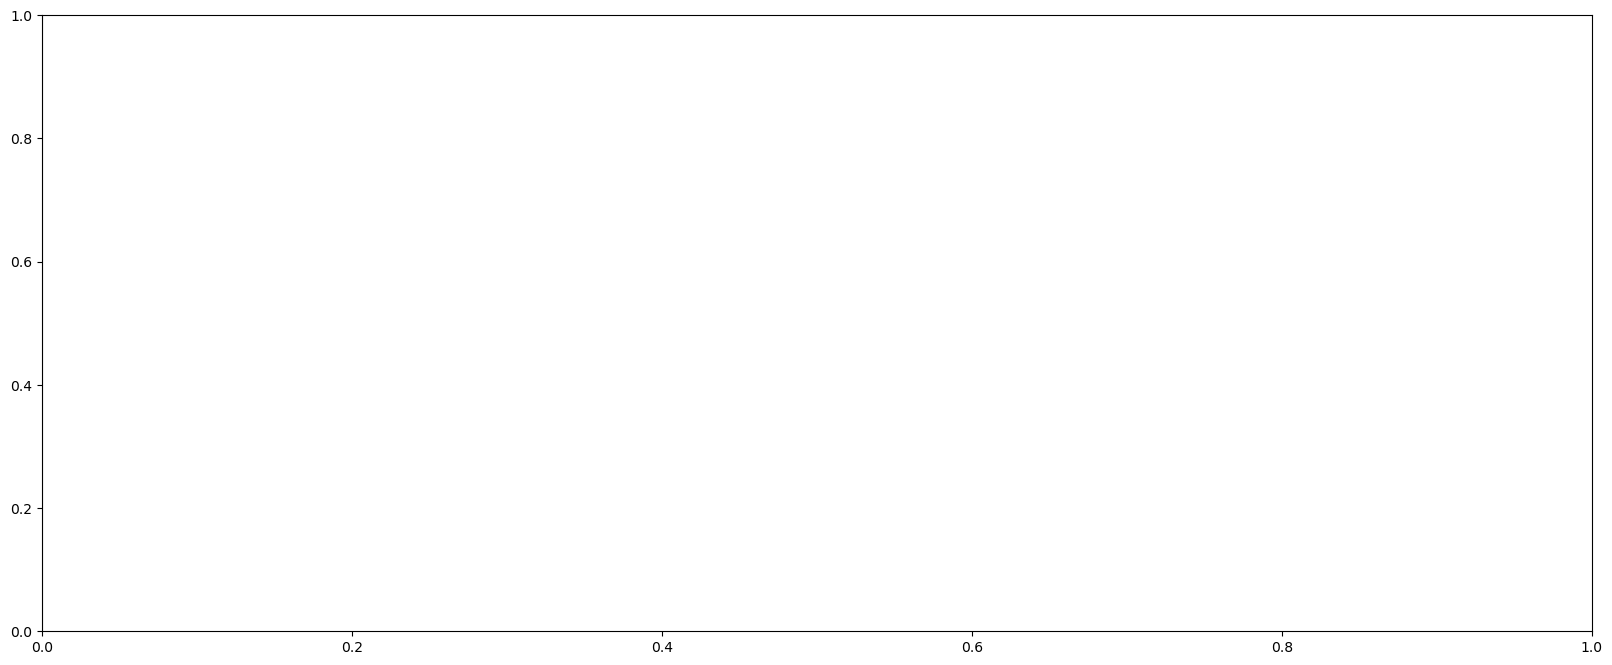

In [ ]:
shap.summary_plot(
    shap_values,
    features_masked_flat_clean_normal,
    feature_names=feature_names,  
    max_display=10,
    #show=False,
    plot_size=(20, 8)
)

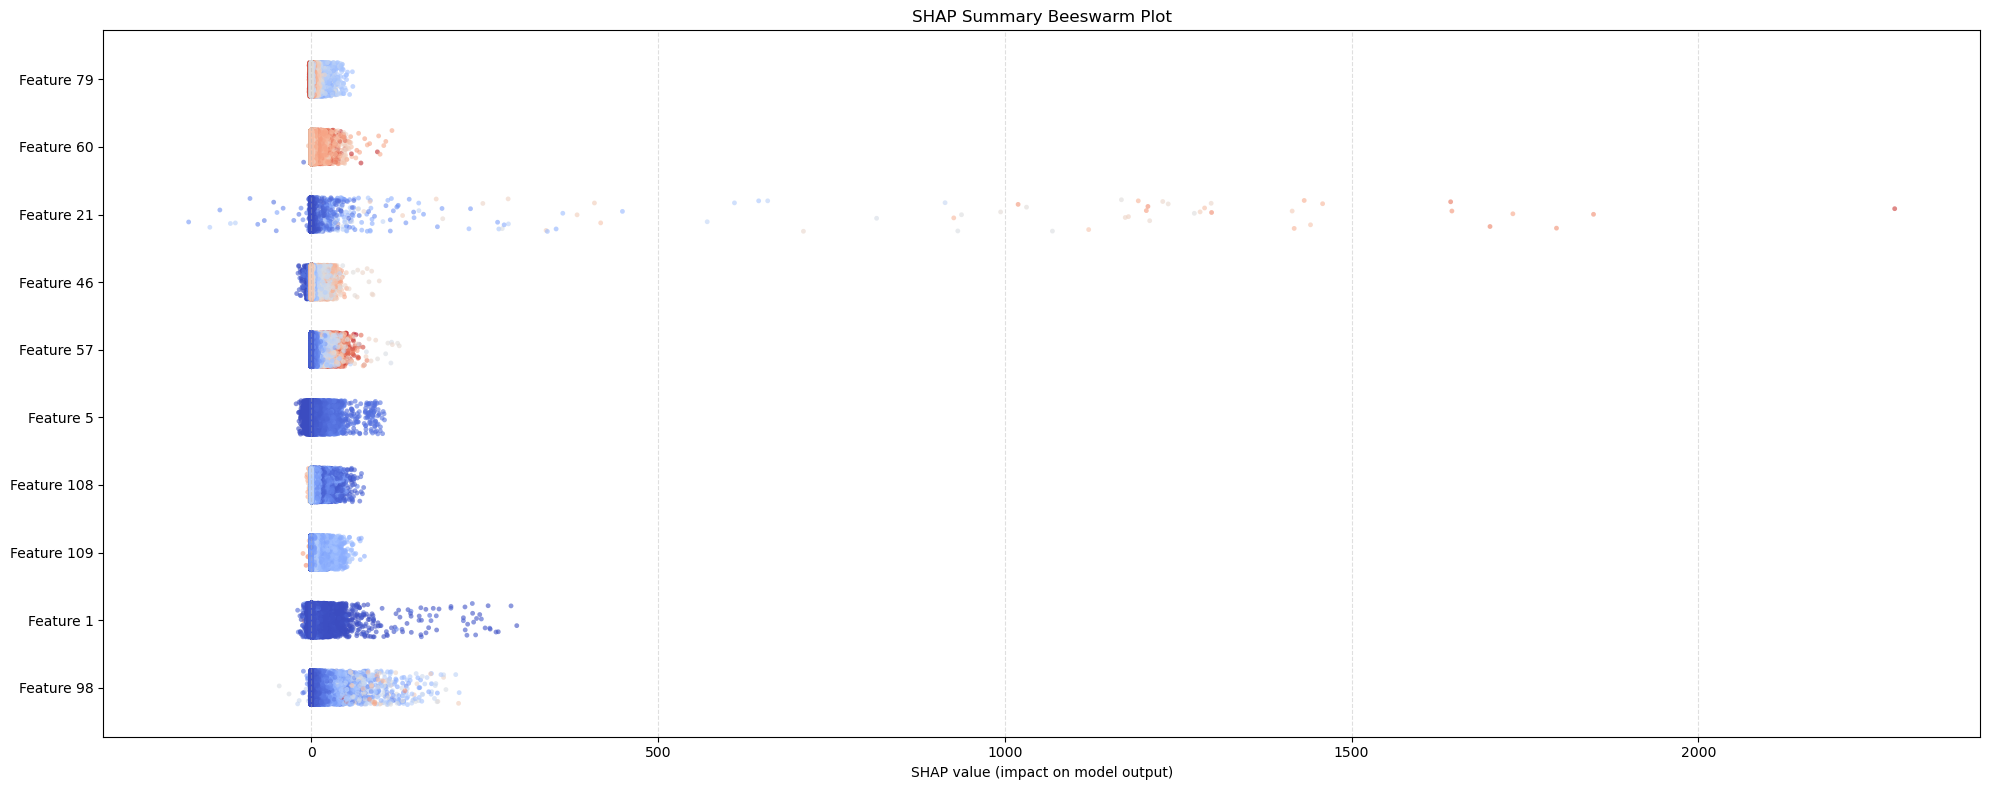

In [ ]:
import shap
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def shap_summary_beeswarm_only(shap_values, features, feature_names=None, max_display=10, plot_size=(20, 8)):
    """
    Create a SHAP summary beeswarm plot (custom, no density/distribution overlay).
    """
    if isinstance(shap_values, shap.Explanation):
        shap_values = shap_values.values

    # Convert to numpy
    shap_values = np.array(shap_values)
    features = np.array(features)

    if feature_names is None:
        feature_names = [f"Feature {i}" for i in range(features.shape[1])]

    # Compute mean |SHAP| for sorting
    mean_abs_shap = np.abs(shap_values).mean(axis=0)
    top_indices = np.argsort(mean_abs_shap)[::-1][:max_display]

    fig, ax = plt.subplots(figsize=plot_size)

    # Plot feature by feature
    for i, idx in enumerate(top_indices):
        shap_vals = shap_values[:, idx]
        feat_vals = features[:, idx]

        # Normalize feature values for color mapping
        cmap = plt.get_cmap("coolwarm")
        cvals = (feat_vals - np.min(feat_vals)) / (np.max(feat_vals) - np.min(feat_vals) + 1e-9)

        # Jitter vertically to create beeswarm effect
        y = np.ones_like(shap_vals) * i + (np.random.rand(len(shap_vals)) - 0.5) * 0.5

        # Scatter plot of SHAP values (beeswarm)
        ax.scatter(shap_vals, y, c=cvals, cmap=cmap, alpha=0.6, s=12, edgecolors='none')

    # Style and labels
    ax.set_yticks(range(len(top_indices)))
    ax.set_yticklabels([feature_names[j] for j in top_indices])
    ax.set_xlabel("SHAP value (impact on model output)")
    ax.set_ylabel("")
    ax.grid(True, axis="x", linestyle="--", alpha=0.4)
    ax.set_title("SHAP Summary Beeswarm Plot")
    plt.tight_layout()
    plt.show()

# Example usage
shap_summary_beeswarm_only(shap_values, features_masked_flat_clean_normal,  max_display=10)


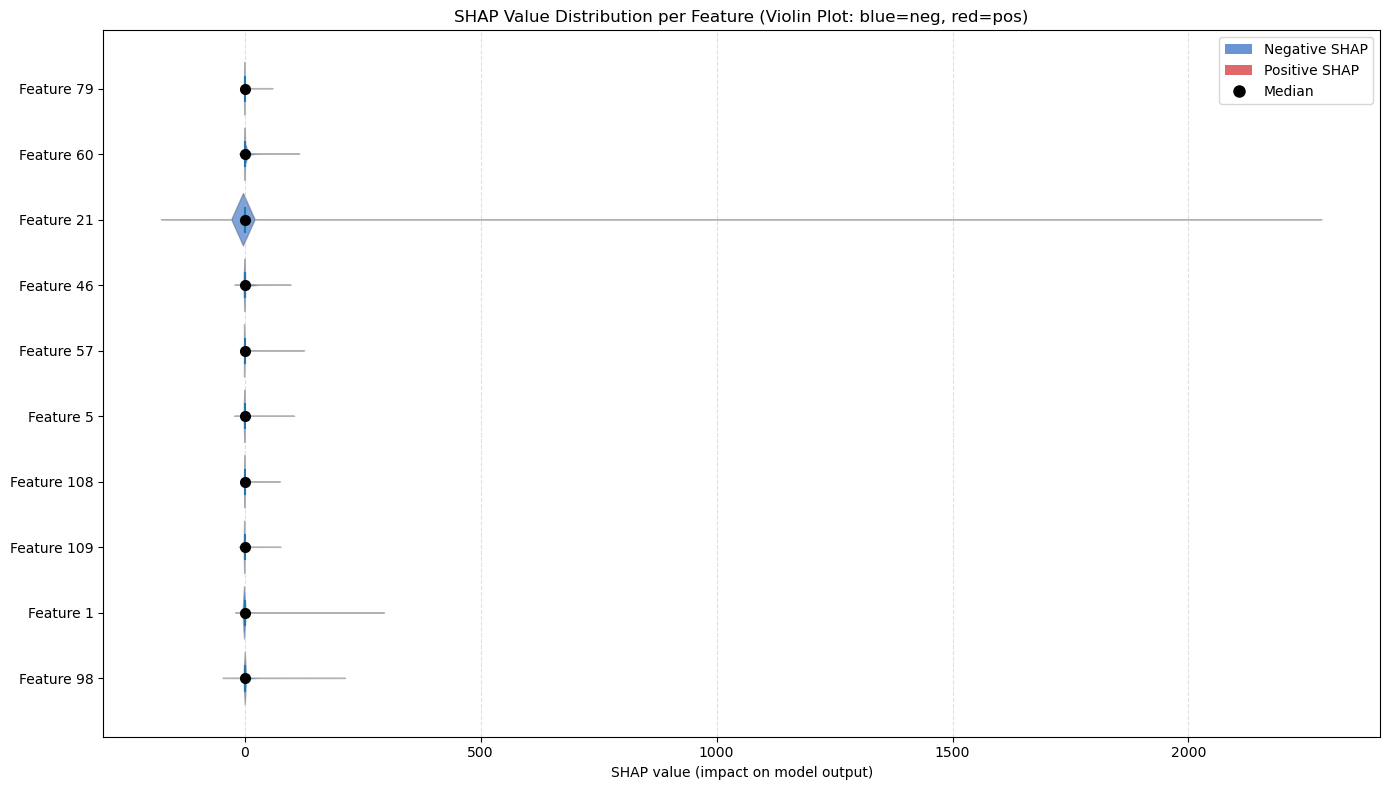

In [ ]:
import shap
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

def shap_violin_distributions(
    shap_values, 
    features, 
    feature_names=None, 
    max_display=10, 
    plot_size=(14,8),
):
    """
    Plot SHAP value distributions with violin plots colored by direction (red/blue).
    No beeswarm, just violin per feature, sorted by mean(|SHAP|).
    """
    # Handle SHAP Explanation objects
    if isinstance(shap_values, shap.Explanation):
        shap_vals = shap_values.values
    else:
        shap_vals = np.array(shap_values)
        
    features = np.array(features)
    
    if feature_names is None:
        feature_names = [f"Feature {i}" for i in range(features.shape[1])]
    
    # Select top features by mean(|SHAP|)
    mean_abs_shap = np.abs(shap_vals).mean(axis=0)
    top_idx = np.argsort(mean_abs_shap)[::-1][:max_display]
    top_names = [feature_names[i] for i in top_idx]

    # Prepare SHAP value matrix for plotting
    top_shap = shap_vals[:, top_idx]
    
    # Create colors for violin halves: negative = blue; positive = red
    neg_color = "#2a65c0"  # blue
    pos_color = "#d52828"  # red

    fig, ax = plt.subplots(figsize=plot_size)
    parts = ax.violinplot(
        top_shap, 
        vert=False, 
        showmeans=False, 
        showmedians=True, 
        showextrema=False, 
        widths=0.8
    )

    # Custom color the violins halves
    for i, pc in enumerate(parts['bodies']):
        vals = top_shap[:,i]
        # To color negative vs positive: 
        # we separate the halves by x-values
        idx = i
        # Get the underlying path vertices of violin
        verts = pc.get_paths()[0].vertices
        mean_x = verts[:,0].mean()
        split = verts[:,0] > mean_x
        # Color positive half (right)
        pc.set_facecolor("none")
        # Draw left half (negative)
        ax.fill_betweenx(
            verts[~split,1], verts[~split,0], mean_x, 
            facecolor=neg_color, alpha=0.6
        )
        # Draw right half (positive)
        ax.fill_betweenx(
            verts[split,1], mean_x, verts[split,0], 
            facecolor=pos_color, alpha=0.6
        )

    # Overlay median dots
    medians = np.median(top_shap, axis=0)
    for i, med in enumerate(medians):
        y = i+1
        ax.plot(med, y, marker='o', color='k', markersize=7, zorder=3)
    
    # Axes formatting
    ax.set_yticks(np.arange(1, len(top_names)+1))
    ax.set_yticklabels(top_names)
    ax.set_xlabel("SHAP value (impact on model output)")
    ax.set_ylabel("")
    ax.set_title("SHAP Value Distribution per Feature (Violin Plot: blue=neg, red=pos)")
    ax.grid(True, axis="x", linestyle="--", alpha=0.4)

    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor=neg_color, label="Negative SHAP", alpha=0.7, edgecolor='none'),
        Patch(facecolor=pos_color, label="Positive SHAP", alpha=0.7, edgecolor='none'),
        plt.Line2D([0], [0], marker='o', color='k', label='Median', markersize=8, linestyle='None')
    ]
    ax.legend(handles=legend_elements, loc="best")
    plt.tight_layout()
    plt.show()

# Example usage:
shap_violin_distributions(shap_values, features_masked_flat_clean_normal, max_display=10)


In [12]:
print(features_masked_flat_clean_normal.shape)
print(shap_values.shape)

(245636, 110)
(245636, 110)


In [13]:
# %%
#os.chdir("/gxfs_work1/cau/sunms498/work/david/NN4SedRatePred/models/MLP/SedRate_MAR/models_torch/")


from os import walk  
feature_path = Path(Path() / "../../data/interim/inputfeatures/SedTOCFeaturesnoNAN_MAR_CS_men/")
X_mean = np.load(Path(feature_path / "features_mean.npy")).astype(float)
X_std = np.load(Path(feature_path / "features_std.npy")).astype(float)

#dataset_path = Path(Path().resolve().parents[2] / "Data" / "restrepoKNNsTOC" / "WorldFeaturesAll")#ChlorWorldFeatures
dataset_path = Path("../../data/interim/worldfeatures/WorldFeaturesAllnoNaN_SedTOC_predict_men/")
files = []

for (dirpath, dirnames, filenames) in walk(dataset_path):
    files.extend(filenames)
    break

files.sort()


features = np.load(Path(dataset_path / files[0]))
#"""
#model = FEA(layer_width)
#model.load_state_dict(torch.load("/gxfs_work1/cau/sunms498/work/toc-neural-nets/SelectFeaturesRun/FEAmodel_test0_75.pth"))

model.eval()
enable_dropout(model) #for mc dropout

chunk_shape = [6,4320] #360 chunks

np.random.seed(42)
torch.manual_seed(42)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu') #'cuda:0' if torch.cuda.is_available() else 
#print(physical_devices)
model.to(device)
print(device)
model.double()


#"""
first_run = True
ii = 0
features = np.load(Path(dataset_path / files[0]))

chunk_shape = [6,4320] #360 chunks


first_run = True
ii = 0

for count, file in enumerate(files):
    features = np.load(Path(dataset_path / file))
    features = np.divide((features - X_mean), X_std)

    features = torch.tensor(features)
    features = features.to(device)

    # Perform multiple forward passes with dropout
    num_samples = 100  # Adjust this based on your requirements
    predictions_sum = np.zeros((num_samples, chunk_shape[0], chunk_shape[1]))

    with torch.no_grad():
        for i in range(num_samples):
            _, predictions = model(features) #decoded, 
            #predictions = (predictions*labels_std)+labels_mean
            #predictions = F.softmax(predictions, dim=1)  # If you're using softmax

            # Store predictions for later averaging
            predictions_sum[i] = predictions.cpu().detach().numpy().reshape(chunk_shape)

    # Average predictions over all samples
    predictions_avg = np.mean(predictions_sum, axis=0)
    predictions_var = np.var(predictions_sum, axis=0)

    if first_run:
        prediction_map2 = predictions_avg
        prediction_map2_var = predictions_var
        first_run = False
    else:
        prediction_map2 = np.append(prediction_map2, predictions_avg, axis=0)
        prediction_map2_var = np.append(prediction_map2_var, predictions_var, axis=0)

    ii += 1
    #if ii == 359:
    print("Prediction " + str(ii) + " done!")

#del features
gc.collect()
"""    
land_file = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/island_map.npy")
land_map = np.load(land_file)
land_map[np.isnan(land_map)] = 1
#prediction_map2[land_map] = 0

#plt.figure(figsize=[25,15], dpi=200)
import matplotlib.colors as mcolors
#prediction_map2 = np.rot90(np.rot90(np.fliplr(prediction_map2)))
plt.figure(figsize=[25, 15], dpi=50)
#prediction_map2[land_map] = 0
plt.imshow(prediction_map2, norm=mcolors.LogNorm(vmin=1e1, vmax=1e2),cmap="cubehelix")
cbar = plt.colorbar()
"""


#np.save("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_SedRate/hyperparameter_optimization/prediction_map_SedRate_CS_supervised_"+str(layer_widths), prediction_map2)

# %%
from matplotlib.colors import LogNorm
land_file = "../../data/raw/island_map.npy"
land_map = np.load(land_file)
land_map[np.isnan(land_map)] = 1
#prediction_map2[land_map] = 0

#plt.figure(figsize=[25,15], dpi=200)
import matplotlib.colors as mcolors
prediction_map2 = np.rot90(np.rot90(np.fliplr(prediction_map2)))
plt.figure(figsize=[25, 15], dpi=50)
#prediction_map2[land_map] = 0
plt.imshow(prediction_map2,vmax = 500, cmap="cubehelix")#norm=LogNorm(vmin = 1e-2, vmax = 1),
cbar = plt.colorbar()

# %%
np.save("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_SedRate/hyperparameter_optimization/prediction_map_MAR_CS_nn_new", prediction_map2)

# %%

cuda:0


TypeError: buildDNN.<locals>.MTLNN.forward() missing 1 required positional argument: 'task_id'

In [ ]:
nanmax_indices